# 1. Human Activity Recognition Using Kernel-Based Multi-Class Support Vector Machines and Five Optimization Algorithms
### Notebook 05 of 5 - Optimizer: **Adam**
Assignment 4 - Kernel-Based Multi-Class SVM implemented from scratch with NumPy.

## 2. Abstract
This notebook is one of five companion notebooks of Assignment 4. All five train the **same** model: a
kernelized, direct multi-class Support Vector Machine (Crammer-Singer hinge loss with RKHS regularisation)
written from scratch in NumPy, with the **RBF kernel** as the primary kernel. The task is to recognise six
human activities from smartphone accelerometer and gyroscope features (UCI HAR dataset, 561 features,
30 volunteers). The notebooks differ only in the optimizer that minimises the objective:
GD, SGD, Mini-Batch GD, AdaGrad and Adam. Data, preprocessing, kernel, kernel basis, initial parameters,
regularisation, objective, epoch budget and metrics are identical, so the comparison is controlled.
**This notebook focuses on Adam.**

## 3. Problem Statement
Smartphones carry an accelerometer and a gyroscope. From a 2.56-second window of these signals we want to
decide **what the person is doing**: walking, walking upstairs, walking downstairs, sitting, standing or
lying down. This is a real-world problem (elderly monitoring, fitness tracking, health applications) and a
genuine **multi-class** problem with **K = 6** classes. Some classes are easy to separate (moving vs. static),
while others overlap strongly (sitting vs. standing), so a non-linear decision boundary may help.

## 4. Project Objectives
1. Implement RBF, polynomial, linear (and exploratory sigmoid) kernels manually.
2. Implement a genuine kernelized direct multi-class SVM via the Representer Theorem.
3. Implement five optimizers manually (GD, SGD, Mini-Batch GD, AdaGrad, Adam) on the same objective.
4. Prevent data leakage (subject-aware validation, statistics fitted on training data only).
5. Select the kernel configuration on validation data, then compare optimizers fairly.
6. Evaluate on the untouched official test subjects with Macro F1 as the primary metric.
7. Compare against a Linear SVM and a scikit-learn `SVC` reference baseline.

## 5. Dataset Description
**UCI Human Activity Recognition Using Smartphones** (Anguita et al., ESANN 2013).

| Item | Value |
|---|---|
| Source (UCI) | https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones |
| Kaggle mirror | https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones |
| Licence | CC BY 4.0 (UCI listing); the original README asks to cite [1] and prohibits commercial use |
| Volunteers | 30 (age 19-48), Samsung Galaxy S II on the waist |
| Signals | 3-axial accelerometer + gyroscope, 50 Hz, windows of 2.56 s with 50% overlap |
| Features | 561 time- and frequency-domain features, already scaled to [-1, 1] by the authors |
| Official split | 7,352 training windows (21 subjects) / 2,947 test windows (9 different subjects) |
| Classes | WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING |

The loader below accepts both the original UCI text files and the Kaggle CSV version.

## 6. Library Imports
Only NumPy / pandas / Matplotlib are used for the model. scikit-learn is used **only** for
`GroupShuffleSplit`, for verifying the manual metrics, for ROC-AUC, and for the separate `SVC` reference baseline.
The project's helper modules are inlined below so the notebook runs stand-alone on Kaggle.

In [1]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=4, suppress=True)

# ---- output folders: /kaggle/working on Kaggle, the project root locally
ON_KAGGLE = os.path.isdir("/kaggle/working")
if ON_KAGGLE:
    OUT = "/kaggle/working"
else:
    OUT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RESULTS = os.path.join(OUT, "results"); MODELS = os.path.join(OUT, "models")
for p in (RESULTS, MODELS, os.path.join(RESULTS, "figures"), os.path.join(RESULTS, "metrics"),
          os.path.join(RESULTS, "training_histories")):
    os.makedirs(p, exist_ok=True)
print("NumPy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("Kaggle:", ON_KAGGLE, "| outputs ->", OUT)

NumPy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2
Kaggle: False | outputs -> /home/claude/A4/Assignment_4_Kernel_Multiclass_SVM


**Helper code - data loading** (`src/dataset_loader.py`)

In [2]:
# ===== inlined from src/dataset_loader.py =====
"""Dataset loading for the UCI Human Activity Recognition (HAR) Using Smartphones dataset.

Two on-disk layouts are supported so the same code runs locally, in VS Code and on Kaggle:

1. The official UCI layout ("UCI HAR Dataset/train/X_train.txt", ...), as distributed by
   https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones
2. The Kaggle CSV layout (train.csv / test.csv with "subject" and "Activity" columns), as in
   https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones

Both contain the same 10,299 windows (7,352 train / 2,947 test), 561 features and 6 activities,
and the same official subject-based train/test partition (21 train subjects / 9 test subjects).
"""
import os
import glob
import numpy as np
import pandas as pd

# Official class order from activity_labels.txt (ids 1..6 -> encoded 0..5).
ACTIVITY_LABELS = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
                   "SITTING", "STANDING", "LAYING"]


def _candidate_roots():
    """Folders in which the dataset may live (local project, notebooks folder, Kaggle)."""
    here = os.getcwd()
    roots = [os.path.join(here, "data"), os.path.join(here, "..", "data"), here,
             "/kaggle/input"]
    env = os.environ.get("HAR_DATA_DIR")
    if env:
        roots.insert(0, env)
    return [r for r in roots if os.path.isdir(r)]


def find_dataset():
    """Return (layout, path). layout is 'uci' (folder with train/X_train.txt) or 'kaggle' (folder with train.csv)."""
    for root in _candidate_roots():
        for hit in glob.glob(os.path.join(root, "**", "X_train.txt"), recursive=True):
            folder = os.path.dirname(os.path.dirname(hit))  # .../UCI HAR Dataset
            if os.path.exists(os.path.join(folder, "features.txt")):
                return "uci", folder
        for hit in glob.glob(os.path.join(root, "**", "train.csv"), recursive=True):
            folder = os.path.dirname(hit)
            if os.path.exists(os.path.join(folder, "test.csv")):
                head = pd.read_csv(hit, nrows=2)
                if "Activity" in head.columns and "subject" in head.columns:
                    return "kaggle", folder
    raise FileNotFoundError(
        "UCI HAR dataset not found. Put the 'UCI HAR Dataset' folder inside data/ "
        "(see data/README.md) or attach the Kaggle dataset "
        "'uciml/human-activity-recognition-with-smartphones' to the notebook.")


def unique_feature_names(names):
    """features.txt contains 42 duplicated names (bandsEnergy blocks); append the index to keep them unique."""
    seen, out = {}, []
    for n in names:
        if n in seen:
            seen[n] += 1
            out.append(f"{n}__{seen[n]}")
        else:
            seen[n] = 0
            out.append(n)
    return out


def load_har():
    """Load the official partition.

    Returns a dict with X_train, y_train (activity names), subject_train, X_test, y_test,
    subject_test (pandas objects), feature_names, layout and path.
    """
    layout, path = find_dataset()
    if layout == "uci":
        feats = pd.read_csv(os.path.join(path, "features.txt"), sep=r"\s+", header=None)[1].tolist()
        feats = unique_feature_names(feats)
        id2name = dict(zip(range(1, 7), ACTIVITY_LABELS))
        out = {}
        for part in ("train", "test"):
            X = pd.read_csv(os.path.join(path, part, f"X_{part}.txt"), sep=r"\s+", header=None)
            X.columns = feats
            y = pd.read_csv(os.path.join(path, part, f"y_{part}.txt"), header=None)[0].map(id2name)
            s = pd.read_csv(os.path.join(path, part, f"subject_{part}.txt"), header=None)[0]
            out[f"X_{part}"], out[f"y_{part}"], out[f"subject_{part}"] = X, y.rename("Activity"), s.rename("subject")
        out["feature_names"] = feats
    else:
        out = {}
        for part in ("train", "test"):
            df = pd.read_csv(os.path.join(path, f"{part}.csv"))
            out[f"y_{part}"] = df.pop("Activity")
            out[f"subject_{part}"] = df.pop("subject")
            out[f"X_{part}"] = df
        out["feature_names"] = list(out["X_train"].columns)
    out["layout"], out["path"] = layout, path
    return out


def describe_partition(data):
    """Small verification table: samples, subjects and features per official partition."""
    rows = []
    for part in ("train", "test"):
        rows.append({"partition": part, "samples": len(data[f"X_{part}"]),
                     "features": data[f"X_{part}"].shape[1],
                     "subjects": int(data[f"subject_{part}"].nunique()),
                     "classes": int(data[f"y_{part}"].nunique())})
    return pd.DataFrame(rows)

**Helper code - preprocessing** (`src/preprocessing.py`)

In [3]:
# ===== inlined from src/preprocessing.py =====
"""Preprocessing: label encoding, subject-aware validation split, standardisation,
reproducible kernel-basis selection and the RBF median heuristic.

Every statistic is fitted on the TRAINING split only (no data leakage).
"""
import numpy as np
from sklearn.model_selection import GroupShuffleSplit


SEED = 42


def encode_labels(y, classes=ACTIVITY_LABELS):
    """Map activity names to integers 0..K-1 using the fixed official class order."""
    mapping = {c: i for i, c in enumerate(classes)}
    return np.asarray([mapping[v] for v in y], dtype=np.int64)


def subject_group_split(subjects, val_fraction=0.2, seed=SEED):
    """Split the official training set into train / validation by SUBJECT.

    No volunteer appears in both parts, so validation measures generalisation to new people,
    exactly like the official test set (which contains 9 unseen subjects).
    """
    subjects = np.asarray(subjects)
    gss = GroupShuffleSplit(n_splits=1, test_size=val_fraction, random_state=seed)
    tr, va = next(gss.split(np.zeros(len(subjects)), groups=subjects))
    return np.sort(tr), np.sort(va)


class Standardizer:
    """StandardScaler written out explicitly: z = (x - mean) / std, fitted on training data only."""

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        self.scale_ = np.where(std < 1e-12, 1.0, std)  # constant columns stay unchanged
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=np.float64) - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def select_basis(y, n_basis, seed=SEED):
    """Reproducible class-stratified selection of kernel basis samples (indices into the TRAINING split).

    Each class receives a share proportional to its frequency (at least one sample), so every
    activity is represented among the basis functions. n_basis >= len(y) returns all indices (exact mode).
    """
    y = np.asarray(y)
    n = len(y)
    if n_basis >= n:
        return np.arange(n)
    rng = np.random.default_rng(seed)
    classes, counts = np.unique(y, return_counts=True)
    quota = np.maximum(1, np.floor(counts / n * n_basis).astype(int))
    # distribute the remaining slots to the largest fractional parts
    rest = n_basis - quota.sum()
    if rest > 0:
        frac = counts / n * n_basis - np.floor(counts / n * n_basis)
        for i in np.argsort(-frac)[:rest]:
            quota[i] += 1
    idx = []
    for c, q in zip(classes, quota):
        members = np.flatnonzero(y == c)
        idx.append(rng.choice(members, size=min(q, len(members)), replace=False))
    return np.sort(np.concatenate(idx))


def median_heuristic_gamma(X, n_samples=2000, seed=SEED):
    """gamma = 1 / median(||x_i - x_j||^2) over random pairs of training samples."""
    rng = np.random.default_rng(seed)
    X = np.asarray(X)
    idx = rng.choice(len(X), size=min(n_samples, len(X)), replace=False)
    S = X[idx]
    sq = np.sum(S ** 2, axis=1)
    d2 = np.maximum(sq[:, None] + sq[None, :] - 2.0 * S @ S.T, 0.0)
    iu = np.triu_indices(len(S), k=1)
    return float(1.0 / np.median(d2[iu]))

**Helper code - evaluation metrics** (`src/evaluation.py`)

In [4]:
# ===== inlined from src/evaluation.py =====
"""Evaluation metrics computed manually from the confusion matrix (verified against scikit-learn).

Important distinction:
  * the TRAINING OBJECTIVE is J = hinge + RKHS regularisation (what the optimizers minimise);
  * the EVALUATION METRICS (accuracy, precision, recall, F1, ROC-AUC) measure predictions.
Raw SVM scores are NOT probabilities, so no log-loss is reported. ROC-AUC is computed One-vs-Rest
directly from the decision scores, which is valid because AUC only depends on the ranking of scores.
"""
import numpy as np
import pandas as pd


def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(cm, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return cm


def accuracy(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def per_class_prf(cm):
    """Precision, recall, F1 per class from the confusion matrix (rows = true, columns = predicted)."""
    tp = np.diag(cm).astype(float)
    pred_pos = cm.sum(axis=0).astype(float)
    true_pos = cm.sum(axis=1).astype(float)
    precision = np.divide(tp, pred_pos, out=np.zeros_like(tp), where=pred_pos > 0)
    recall = np.divide(tp, true_pos, out=np.zeros_like(tp), where=true_pos > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return precision, recall, f1, true_pos


def macro_f1(y_true, y_pred, n_classes):
    return float(per_class_prf(confusion_matrix(y_true, y_pred, n_classes))[2].mean())


def ovr_roc_auc(y_true, scores):
    """Macro One-vs-Rest ROC-AUC from raw decision scores (rank based, no probability assumption)."""
    from sklearn.metrics import roc_auc_score
    Y = np.eye(scores.shape[1])[np.asarray(y_true)]
    return float(roc_auc_score(Y, scores, average="macro"))


def evaluate(y_true, y_pred, n_classes, scores=None):
    cm = confusion_matrix(y_true, y_pred, n_classes)
    p, r, f, support = per_class_prf(cm)
    w = support / support.sum()
    out = {"accuracy": accuracy(y_true, y_pred),
           "macro_precision": float(p.mean()), "macro_recall": float(r.mean()), "macro_f1": float(f.mean()),
           "weighted_precision": float(np.sum(w * p)), "weighted_recall": float(np.sum(w * r)),
           "weighted_f1": float(np.sum(w * f)),
           "per_class_precision": p, "per_class_recall": r, "per_class_f1": f, "support": support,
           "confusion_matrix": cm}
    if scores is not None:
        out["roc_auc_ovr_macro"] = ovr_roc_auc(y_true, scores)
    return out


def verify_with_sklearn(y_true, y_pred, metrics):
    """Max absolute difference between the manual metrics and scikit-learn's (should be ~1e-16)."""
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    diffs = [abs(metrics["accuracy"] - accuracy_score(y_true, y_pred))]
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        diffs += [abs(metrics[f"{avg}_precision"] - p), abs(metrics[f"{avg}_recall"] - r), abs(metrics[f"{avg}_f1"] - f)]
    return float(max(diffs))


def classification_report_df(metrics, class_names):
    df = pd.DataFrame({"precision": metrics["per_class_precision"], "recall": metrics["per_class_recall"],
                       "f1": metrics["per_class_f1"], "support": metrics["support"].astype(int)}, index=class_names)
    df.loc["macro avg"] = [metrics["macro_precision"], metrics["macro_recall"], metrics["macro_f1"], int(metrics["support"].sum())]
    df.loc["weighted avg"] = [metrics["weighted_precision"], metrics["weighted_recall"], metrics["weighted_f1"], int(metrics["support"].sum())]
    df["support"] = df["support"].astype(int)
    return df.round(4)

**Helper code - plotting** (`src/visualization.py`)

In [5]:
# ===== inlined from src/visualization.py =====
"""Plotting helpers. Every experimental curve is drawn from values recorded during training."""
import os
import numpy as np
import matplotlib.pyplot as plt

COLORS = {"GD": "#1f77b4", "SGD": "#ff7f0e", "MBGD": "#2ca02c", "AdaGrad": "#9467bd", "Adam": "#d62728"}
NAMES = {"GD": "Gradient Descent", "SGD": "SGD", "MBGD": "Mini-Batch GD", "AdaGrad": "AdaGrad", "Adam": "Adam"}
SHORT_CLASSES = ["WALK", "UP", "DOWN", "SIT", "STAND", "LAY"]
FIG_DIR = "figures"

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def set_fig_dir(path):
    global FIG_DIR
    FIG_DIR = path
    os.makedirs(path, exist_ok=True)


def save(fig, name):
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")
    plt.show()


def class_distribution(y_names_train, y_names_test, order, name="class_distribution.png"):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    tr = [int(np.sum(np.asarray(y_names_train) == c)) for c in order]
    te = [int(np.sum(np.asarray(y_names_test) == c)) for c in order]
    x = np.arange(len(order))
    ax.bar(x - 0.2, tr, 0.4, label="official train", color="#4c72b0")
    ax.bar(x + 0.2, te, 0.4, label="official test", color="#dd8452")
    for i, (a, b) in enumerate(zip(tr, te)):
        ax.text(i - 0.2, a + 15, str(a), ha="center", fontsize=8)
        ax.text(i + 0.2, b + 15, str(b), ha="center", fontsize=8)
    ax.set_xticks(x, order, rotation=20)
    ax.set_ylabel("windows"); ax.set_title("Class distribution (6 activities)"); ax.legend()
    save(fig, name)


def pca_projection(X, y, class_names, name="pca_projection.png"):
    Xc = X - X.mean(0)
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    P = Xc @ Vt[:2].T
    ev = s ** 2 / np.sum(s ** 2)
    fig, ax = plt.subplots(figsize=(7, 5))
    cmap = plt.get_cmap("tab10")
    for k, c in enumerate(class_names):
        m = y == k
        ax.scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, color=cmap(k), label=c)
    ax.set_xlabel(f"PC1 ({100*ev[0]:.1f}% var)"); ax.set_ylabel(f"PC2 ({100*ev[1]:.1f}% var)")
    ax.set_title("PCA projection of the standardised training features\n(visualisation only - not the model's decision space)")
    ax.legend(markerscale=3, fontsize=8)
    save(fig, name)
    return ev


def feature_distributions(df, y_names, features, order, name="feature_distributions.png"):
    fig, axes = plt.subplots(1, len(features), figsize=(4 * len(features), 3.6))
    for ax, f in zip(np.atleast_1d(axes), features):
        data = [df.loc[np.asarray(y_names) == c, f].to_numpy() for c in order]
        ax.boxplot(data, showfliers=False)
        ax.set_xticks(range(1, len(order) + 1), SHORT_CLASSES)
        ax.set_title(f, fontsize=9)
    save(fig, name)


def correlation_heatmap(df, features, name="feature_correlation.png"):
    C = df[features].corr().to_numpy()
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(features)), [f[:22] for f in features], rotation=90, fontsize=7)
    ax.set_yticks(range(len(features)), [f[:22] for f in features], fontsize=7)
    fig.colorbar(im, ax=ax); ax.set_title("Correlation of selected features"); ax.grid(False)
    save(fig, name)


def gram_heatmap(G, y, class_names, title, name):
    order = np.argsort(y, kind="stable")
    fig, ax = plt.subplots(figsize=(6, 5.2))
    im = ax.imshow(G[np.ix_(order, order)], cmap="viridis")
    ys = y[order]
    ticks = [np.flatnonzero(ys == k).mean() for k in range(len(class_names)) if np.any(ys == k)]
    ax.set_xticks(ticks, SHORT_CLASSES[:len(ticks)], fontsize=8); ax.set_yticks(ticks, SHORT_CLASSES[:len(ticks)], fontsize=8)
    ax.set_title(title); ax.grid(False); fig.colorbar(im, ax=ax)
    save(fig, name)


def rbf_similarity_curves(gamma0, multipliers, d2_max, name="rbf_similarity.png"):
    d2 = np.linspace(0, d2_max, 400)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for m in multipliers:
        ax.plot(d2, np.exp(-gamma0 * m * d2), label=f"gamma = {m:g} x median heuristic")
    ax.set_xlabel("squared distance ||x - z||^2 (standardised features)"); ax.set_ylabel("K(x, z)")
    ax.set_title("RBF similarity decays with distance - gamma controls how fast"); ax.legend(fontsize=8)
    save(fig, name)


def decision_boundaries(models, X, y, titles, name):
    """models: list of callables f(grid_points) -> class predictions (2-D synthetic data only)."""
    x0, x1 = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y0, y1 = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    gx, gy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    grid = np.c_[gx.ravel(), gy.ravel()]
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4.4))
    for ax, f, t in zip(np.atleast_1d(axes), models, titles):
        Zp = f(grid).reshape(gx.shape)
        ax.contourf(gx, gy, Zp, alpha=0.25, levels=np.arange(-0.5, 3), cmap="brg")
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap="brg", s=10, edgecolors="k", linewidths=0.2)
        ax.set_title(t, fontsize=10); ax.set_aspect("equal")
    fig.suptitle("SYNTHETIC 2-D demonstration (not the HAR results)", fontsize=10)
    save(fig, name)


def training_curves(histories, keys=("train_obj", "val_obj", "val_acc", "val_f1"), name="training_curves.png",
                    titles=None):
    titles = titles or {"train_obj": "Training objective J", "val_obj": "Validation objective",
                        "val_acc": "Validation accuracy", "val_f1": "Validation Macro F1",
                        "train_acc": "Training accuracy"}
    fig, axes = plt.subplots(1, len(keys), figsize=(4.4 * len(keys), 3.6))
    for ax, k in zip(np.atleast_1d(axes), keys):
        for opt, h in histories.items():
            ax.plot(h[k], color=COLORS.get(opt), label=NAMES.get(opt, opt), lw=1.6)
        ax.set_title(titles.get(k, k)); ax.set_xlabel("epoch")
        if "obj" in k:
            ax.set_yscale("log")
    np.atleast_1d(axes)[0].legend(fontsize=8)
    save(fig, name)


def lr_search_plot(df, opt, name):
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ok = df[~df.diverged]
    ax.semilogx(ok.lr, ok.final_val_macro_f1, "o-", color=COLORS.get(opt))
    for _, r in df[df.diverged].iterrows():
        ax.axvline(r.lr, color="grey", ls=":", lw=1)
    ax.set_xlabel("learning rate"); ax.set_ylabel("final validation Macro F1")
    ax.set_title(f"{NAMES.get(opt, opt)}: learning-rate search (100 epochs each)")
    save(fig, name)


def confusion(cm, class_names, title, name, ax=None):
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(5.6, 4.8))
    ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(len(class_names)), SHORT_CLASSES[:len(class_names)], fontsize=8)
    ax.set_yticks(range(len(class_names)), SHORT_CLASSES[:len(class_names)], fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10); ax.grid(False)
    if own:
        save(fig, name)


def confusion_grid(cms, class_names, name="confusion_matrices_all.png"):
    fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 4))
    for ax, (opt, cm) in zip(np.atleast_1d(axes), cms.items()):
        confusion(cm, class_names, NAMES.get(opt, opt), None, ax=ax)
    save(fig, name)


def bar_compare(values, ylabel, title, name, fmt="{:.3f}", log=False):
    fig, ax = plt.subplots(figsize=(7, 3.6))
    keys = list(values)
    bars = ax.bar([NAMES.get(k, k) for k in keys], [values[k] for k in keys], color=[COLORS.get(k, "#777") for k in keys])
    for bar, k in zip(bars, keys):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), fmt.format(values[k]), ha="center", va="bottom", fontsize=8)
    if log:
        ax.set_yscale("log")
    ax.set_ylabel(ylabel); ax.set_title(title)
    save(fig, name)


def per_class_f1(f1_by_opt, class_names, name="per_class_f1.png"):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = np.arange(len(class_names)); w = 0.8 / len(f1_by_opt)
    for i, (opt, f) in enumerate(f1_by_opt.items()):
        ax.bar(x + (i - len(f1_by_opt) / 2 + 0.5) * w, f, w, color=COLORS.get(opt), label=NAMES.get(opt, opt))
    ax.set_xticks(x, class_names, rotation=15, fontsize=8); ax.set_ylim(0, 1.05)
    ax.set_ylabel("test F1"); ax.set_title("Per-class F1 on the independent test set"); ax.legend(fontsize=7, ncol=5)
    save(fig, name)


def sensitivity_lines(df, x, y, group, title, name, logx=True, xlabel=None):
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    for g, sub in df.groupby(group):
        sub = sub.sort_values(x)
        ax.plot(sub[x], sub[y], "o-", label=f"{group} = {g:g}")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel or x); ax.set_ylabel(y); ax.set_title(title); ax.legend(fontsize=7)
    save(fig, name)

## 7. Dataset Loading

In [6]:
raw = load_har()
print("layout:", raw["layout"], "| path:", raw["path"])
display(describe_partition(raw))
df_tr = raw["X_train"].copy(); df_tr["Activity"] = raw["y_train"].values; df_tr["subject"] = raw["subject_train"].values
print("Shape of the official training table (features + Activity + subject):", df_tr.shape)
show_cols = list(df_tr.columns[:6]) + ["subject", "Activity"]
print("First five records (first 6 of 561 features):"); display(df_tr[show_cols].head())
print("Last five records:"); display(df_tr[show_cols].tail())

layout: uci | path: /home/claude/A4/Assignment_4_Kernel_Multiclass_SVM/notebooks/../data/UCI HAR Dataset


,partition,samples,features,subjects,classes
0,train,7352,561,21,6
1,test,2947,561,9,6


Shape of the official training table (features + Activity + subject): (7352, 563)
First five records (first 6 of 561 features):


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,1,STANDING


Last five records:


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,subject,Activity
7347,0.299665,-0.057193,-0.181233,-0.195387,0.039905,0.077078,30,WALKING_UPSTAIRS
7348,0.273853,-0.007749,-0.147468,-0.235309,0.004816,0.059280,30,WALKING_UPSTAIRS
7349,0.273387,-0.017011,-0.045022,-0.218218,-0.103822,0.274533,30,WALKING_UPSTAIRS
7350,0.289654,-0.018843,-0.158281,-0.219139,-0.111412,0.268893,30,WALKING_UPSTAIRS
7351,0.351503,-0.012423,-0.203867,-0.269270,-0.087212,0.177404,30,WALKING_UPSTAIRS


## 8. Exploratory Data Analysis

In [7]:
X_all = raw["X_train"]
print("Data types:", dict(X_all.dtypes.value_counts()))
print("Missing values (train / test):", int(X_all.isna().sum().sum()), "/", int(raw["X_test"].isna().sum().sum()))
print("Duplicated feature rows in train:", int(X_all.duplicated().sum()))
print("Feature value range: [%.3f, %.3f] (the authors already scaled features to [-1, 1])" % (X_all.values.min(), X_all.values.max()))
REP_FEATURES = ["tBodyAcc-mean()-X", "tGravityAcc-mean()-X", "tBodyAccMag-mean()", "fBodyAccJerk-std()-X",
                "tBodyGyro-std()-X", "angle(X,gravityMean)"]
display(X_all[REP_FEATURES].describe().T.round(4))
counts = raw["y_train"].value_counts().reindex(ACTIVITY_LABELS)
dist = pd.DataFrame({"train": counts, "train %": (100 * counts / counts.sum()).round(2),
                     "test": raw["y_test"].value_counts().reindex(ACTIVITY_LABELS)})
display(dist)
print("Imbalance ratio (largest / smallest class, train): %.2f" % (counts.max() / counts.min()))

Data types: {dtype('float64'): np.int64(561)}
Missing values (train / test): 0 / 0


Duplicated feature rows in train: 0


Feature value range: [-1.000, 1.000] (the authors already scaled features to [-1, 1])


,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,7352.0,0.2745,0.0703,-1.0,0.2630,0.2772,0.2885,1.0000
tGravityAcc-mean()-X,7352.0,0.6641,0.5168,-1.0,0.8049,0.9195,0.9531,0.9915
tBodyAccMag-mean(),7352.0,-0.5439,0.4777,-1.0,-0.9833,-0.8834,-0.1069,1.0000
fBodyAccJerk-std()-X,7352.0,-0.6593,0.3954,-1.0,-0.9924,-0.9627,-0.3221,1.0000
tBodyGyro-std()-X,7352.0,-0.7209,0.3067,-1.0,-0.9881,-0.9115,-0.4779,1.0000
"angle(X,gravityMean)",7352.0,-0.4895,0.5118,-1.0,-0.8121,-0.7094,-0.5091,1.0000


,train,train %,test
Activity,,,
WALKING,1226,16.68,496
WALKING_UPSTAIRS,1073,14.59,471
WALKING_DOWNSTAIRS,986,13.41,420
SITTING,1286,17.49,491
STANDING,1374,18.69,532
LAYING,1407,19.14,537


Imbalance ratio (largest / smallest class, train): 1.43


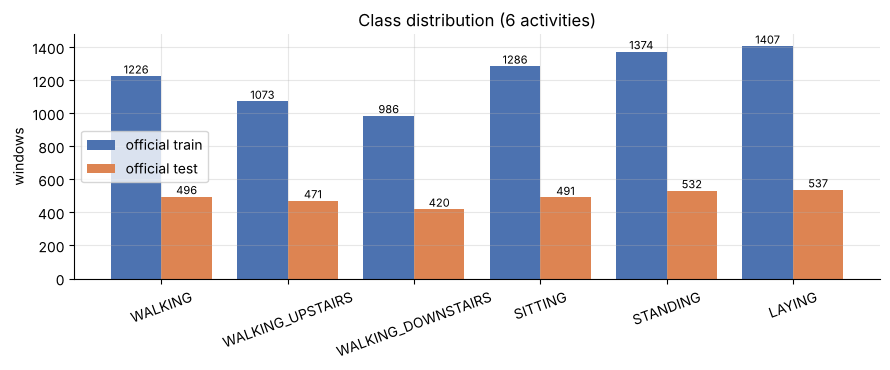

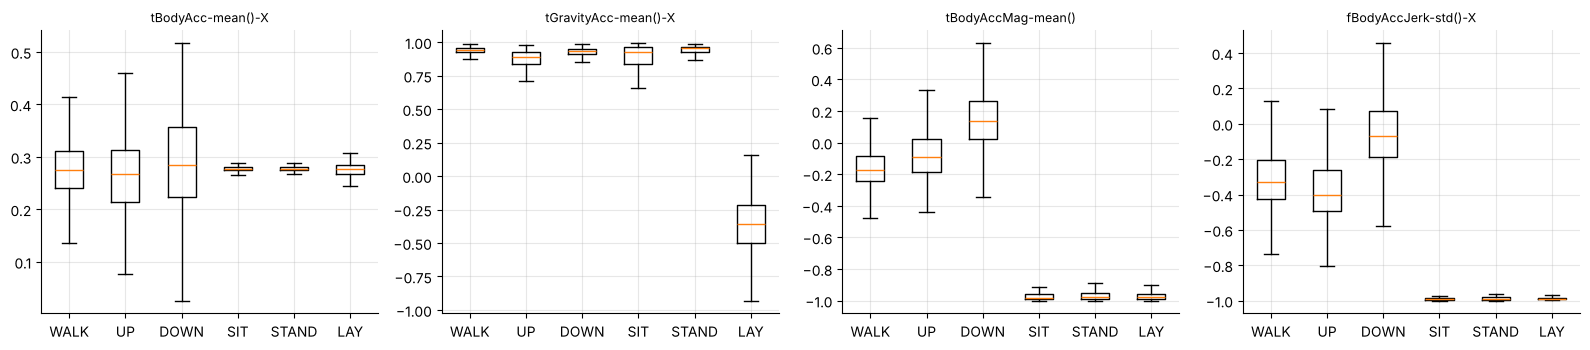

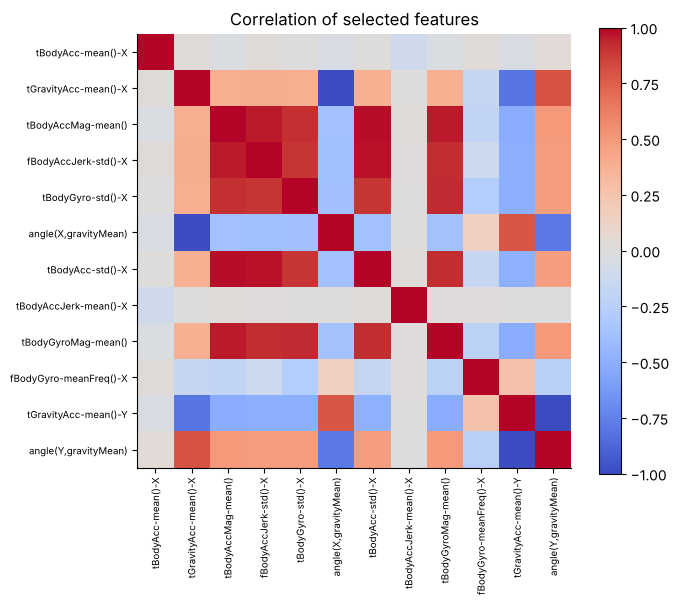

Overall share of |z| > 3 values: 0.982%


,share |z|>3
tGravityAcc-energy()-Y,0.0358
tGravityAcc-energy()-Z,0.0305
tBodyGyro-mean()-Z,0.0301
tGravityAcc-entropy()-Y,0.0277
fBodyAcc-maxInds-Z,0.0272
"fBodyAccJerk-bandsEnergy()-1,24__2",0.0267
fBodyBodyGyroMag-maxInds,0.0253
fBodyBodyGyroJerkMag-energy(),0.0250


Outliers are kept: they are real sensor readings, and the RBF kernel is bounded (0 < k <= 1),
so a single extreme point cannot dominate the decision scores.


In [8]:
set_fig_dir(os.path.join(RESULTS, "figures"))
class_distribution(raw["y_train"], raw["y_test"], ACTIVITY_LABELS, name="eda_class_distribution.png")
feature_distributions(X_all, raw["y_train"], REP_FEATURES[:4], ACTIVITY_LABELS, name="eda_feature_distributions.png")
CORR_FEATURES = REP_FEATURES + ["tBodyAcc-std()-X", "tBodyAccJerk-mean()-X", "tBodyGyroMag-mean()",
                                "fBodyGyro-meanFreq()-X", "tGravityAcc-mean()-Y", "angle(Y,gravityMean)"]
correlation_heatmap(X_all, CORR_FEATURES, name="eda_feature_correlation.png")
# Outliers: share of standardised values with |z| > 3 per feature (computed on the official training set)
z = (X_all - X_all.mean()) / X_all.std().replace(0, 1)
out_share = (z.abs() > 3).mean().sort_values(ascending=False)
print("Overall share of |z| > 3 values: %.3f%%" % (100 * (z.abs() > 3).values.mean()))
display(out_share.head(8).rename("share |z|>3").to_frame().round(4))
print("Outliers are kept: they are real sensor readings, and the RBF kernel is bounded (0 < k <= 1),")
print("so a single extreme point cannot dominate the decision scores.")

**EDA observations.** No missing values; the six classes are reasonably balanced (largest/smallest
ratio about 1.4), so Macro F1 is a fair primary metric. Static postures (sitting, standing, lying) and dynamic
activities (walking variants) are clearly separated in the PCA plot, while **SITTING and STANDING overlap
strongly** - the hardest pair for any classifier. Many features are strongly correlated (they are derived from the
same signals).

## 9. Preprocessing
1. **Feature / target separation** - the 561 numeric features form $X$; `Activity` is the target; the
   `subject` id is kept **only** for splitting and is **never** used as a feature.
2. **Label encoding** - fixed official order WALKING=0, ..., LAYING=5.
3. **Subject-aware validation split** - the official training set (21 subjects) is split with
   `GroupShuffleSplit(test_size=0.2, random_state=42)` so that validation subjects are unseen, like the official
   test subjects. The **official test set is used only once, for the final evaluation**.
4. **Standardisation** - mean and standard deviation are computed on the training split only and applied to
   validation and test.
5. **Kernel basis** - selected **only from the training split** (class-stratified, seed 42).
6. **RBF $\gamma$** - median heuristic computed on the training split only.

training subjects  : [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(26), np.int64(28), np.int64(29), np.int64(30)]
validation subjects: [np.int64(1), np.int64(3), np.int64(15), np.int64(25), np.int64(27)]
test subjects      : [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
sizes  train / val / test: 5551 / 1801 / 2947


,train,validation,test
WALKING,0.160,0.188,0.168
WALKING_UPSTAIRS,0.144,0.153,0.160
WALKING_DOWNSTAIRS,0.134,0.134,0.143
SITTING,0.179,0.163,0.167
STANDING,0.190,0.178,0.181
LAYING,0.194,0.184,0.182


standardised train: mean 1.20e-15, std 1.000


median-heuristic gamma0 = 1.0774e-03


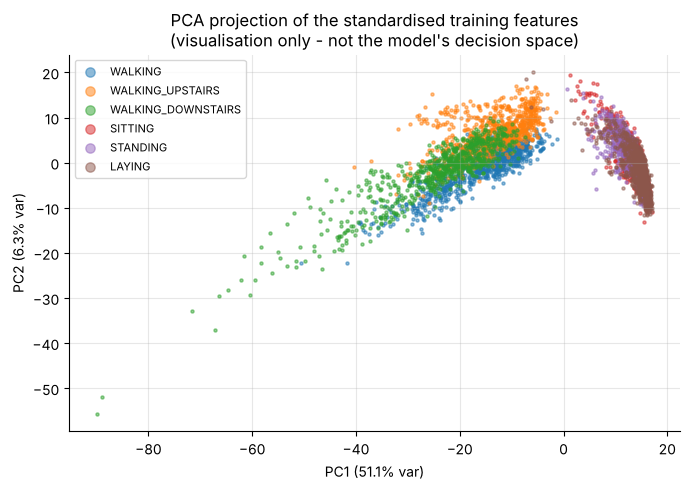

In [9]:
y_full = encode_labels(raw["y_train"]); y_test_enc = encode_labels(raw["y_test"])
subjects = raw["subject_train"].to_numpy()
tr_idx, va_idx = subject_group_split(subjects, val_fraction=0.2, seed=SEED)
print("training subjects  :", sorted(np.unique(subjects[tr_idx])))
print("validation subjects:", sorted(np.unique(subjects[va_idx])))
print("test subjects      :", sorted(raw["subject_test"].unique()))
assert set(subjects[tr_idx]).isdisjoint(subjects[va_idx]), "subject leakage!"
assert set(subjects).isdisjoint(set(raw["subject_test"])), "official partition broken!"
scaler = Standardizer().fit(raw["X_train"].to_numpy(float)[tr_idx])          # training split ONLY
X_tr_check = scaler.transform(raw["X_train"].to_numpy(float)[tr_idx])
print("sizes  train / val / test:", len(tr_idx), "/", len(va_idx), "/", len(y_test_enc))
props = pd.DataFrame({"train": np.bincount(y_full[tr_idx]) / len(tr_idx), "validation": np.bincount(y_full[va_idx]) / len(va_idx),
                      "test": np.bincount(y_test_enc) / len(y_test_enc)}, index=ACTIVITY_LABELS).round(3)
display(props)
print("standardised train: mean %.2e, std %.3f" % (X_tr_check.mean(), X_tr_check.std()))
gamma0_check = median_heuristic_gamma(X_tr_check, seed=SEED)
print("median-heuristic gamma0 = %.4e" % gamma0_check)
pca_ev = pca_projection(X_tr_check, y_full[tr_idx], ACTIVITY_LABELS, name="eda_pca_projection.png")

## 10. SVM Theory
**Hyperplane and margin.** A linear classifier uses a hyperplane $w^\top x + b = 0$. Many hyperplanes may
separate two classes; the **Support Vector Machine** chooses the one with the **maximum margin**, i.e. the
largest distance $2/\lVert w\rVert$ between the two parallel hyperplanes $w^\top x + b = \pm 1$.
The training points lying on (or inside) the margin are the **support vectors**: only they determine the
solution.

* **Hard margin:** $\min \tfrac12\lVert w\rVert^2$ s.t. $y_i(w^\top x_i+b)\ge 1$ - requires perfectly separable data.
* **Soft margin:** allows violations through the hinge loss $\max(0, 1 - y_i f(x_i))$:
  $\min_w \tfrac{\lambda}{2}\lVert w\rVert^2 + \tfrac1N\sum_i \max(0, 1-y_i f(x_i))$. The **regularisation**
  coefficient $\lambda$ trades margin width against training errors (it plays the role of $1/(CN)$ in the
  classical $C$-formulation).

**Linear vs. non-linear classification.** If the classes are arranged, for example, as concentric rings,
no straight line (hyperplane) in the original space can separate them. Mapping the data to a richer feature
space $\phi(x)$ can make them linearly separable there; the separating hyperplane in feature space
corresponds to a **curved** boundary in the original space.

## 11. Kernel Trick Explanation
A **kernel** is a function $k(x,z) = \langle \phi(x), \phi(z)\rangle$ that returns the inner product of two
samples in a (possibly infinite-dimensional) feature space **without constructing $\phi$ explicitly**.
For the RBF kernel the feature space is infinite-dimensional, yet $k(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$
costs only one distance computation - this is the **kernel trick**.

* **Kernel (Gram) matrix:** $G_{ij} = k(z_i, z_j)$ collects all pairwise similarities.
* **Positive semidefinite (PSD):** a valid (Mercer) kernel produces $G \succeq 0$ for every finite set of
  points, i.e. $a^\top G a \ge 0$. PSD guarantees that $k$ is a real inner product, that
  $\lVert f\rVert^2 = a^\top G a \ge 0$, and that the regularised objective is convex.
* **RKHS:** every PSD kernel defines a *Reproducing Kernel Hilbert Space* $\mathcal H$ of functions
  $f(x)=\sum_j a_j k(x, z_j)$ with norm $\lVert f\rVert_{\mathcal H}^2 = a^\top G a$ and the reproducing
  property $f(x) = \langle f, k(\cdot, x)\rangle_{\mathcal H}$.
* **Representer Theorem:** the minimiser of (loss on the training data) + $\lambda\lVert f\rVert^2_{\mathcal H}$
  can be written as a weighted sum of kernels centred at the training points. We therefore optimise the
  coefficient matrix $A$ instead of an (infinite) weight vector.

**Kernels implemented** (Section 15):

| Kernel | Formula | Notes |
|---|---|---|
| Linear | $x^\top z$ | identical to the Linear SVM of the previous assignment |
| Polynomial | $(\gamma x^\top z + r)^d$ | feature interactions up to degree $d$; large $d$ -> overfitting / numerical growth |
| RBF | $\exp(-\gamma\lVert x-z\rVert^2)$ | local similarity in (0, 1], $k(x,x)=1$; **primary kernel** |
| Sigmoid | $\tanh(\gamma x^\top z + r)$ | inspired by neural activations; **not PSD in general** -> exploratory only |

**Effect of RBF $\gamma$.** Small $\gamma$: every sample influences far-away points, boundaries are smooth
(close to linear, risk of underfitting). Large $\gamma$: each sample influences only its close neighbourhood,
boundaries become very wiggly (risk of overfitting; $G \to I$). We initialise $\gamma$ with the **median
heuristic** $\gamma_0 = 1/\mathrm{median}\lVert x_i-x_j\rVert^2$ and tune a multiplier on validation data.

**Feature scaling matters for RBF:** the kernel depends on Euclidean distances, so a feature with a larger
numeric range would dominate the distance. Standardisation puts all 561 features on the same scale.

## 12. Multi-Class Classification Theory
Binary SVMs separate two classes. Common multi-class strategies:

* **One-vs-Rest (OvR):** K binary SVMs, class k against all others; predict the largest score.
* **One-vs-One (OvO):** K(K-1)/2 = 15 binary SVMs, one per pair; predict by voting
  (scikit-learn `SVC` uses OvO internally).
* **Direct multi-class (Crammer-Singer):** a **single** optimisation problem with one score function per
  class, trained jointly. The loss asks the correct class to beat the **best wrong class** by a margin of 1.

We use the direct Crammer-Singer formulation: one objective, all classes coupled, no voting.

## 13. Mathematical Objective
Let $Z = \{z_1,\dots,z_M\}$ be the kernel **basis** (training samples), $H_{ij} = k(x_i, z_j)$ the
$N\times M$ kernel feature matrix, $G_{ij} = k(z_i, z_j)$ the $M\times M$ basis Gram matrix,
$A\in\mathbb R^{M\times K}$ the coefficients and $b\in\mathbb R^K$ the biases.

**Scores:** $S = HA + b$, i.e. $f_k(x) = \sum_j A_{jk}\,k(x, z_j) + b_k$; **prediction** $\hat y = \arg\max_k S_{ik}$.

**Objective (regularised Crammer-Singer kernel hinge loss):**
$$J(A,b) = \frac{\lambda}{2}\,\mathrm{Tr}(A^\top G A) + \frac1N\sum_{i=1}^N L_i,\qquad
L_i = \max\Big(0,\; 1 + \max_{j\ne y_i} S_{ij} - S_{i,y_i}\Big).$$
$\mathrm{Tr}(A^\top G A) = \sum_k \lVert f_k\rVert^2_{\mathcal H}$ is the **RKHS norm** (not an ordinary
$\lVert A\rVert^2$ penalty). The bias is not regularised.

**Subgradient.** Define $D\in\mathbb R^{N\times K}$: if sample $i$ violates the margin ($L_i>0$), put $-1$ at
the true class $y_i$ and $+1$ at the highest-scoring wrong class $j^*$; otherwise the row is zero
(ties: the smallest class index among the maximal wrong classes).
$$\frac{\partial J}{\partial A} = \frac{H^\top D}{N} + \lambda G A,\qquad \frac{\partial J}{\partial b} = \frac{1}{N}\sum_i D_{i,:}.$$
For SGD / mini-batches the data term is averaged over the batch $B$ ($H_B^\top D_B/|B|$) while the
regularisation gradient $\lambda G A$ is kept exactly - this is an unbiased estimate of the full subgradient.

**Why the boundary is non-linear:** $f_k(x)$ is a weighted sum of RBF bumps centred at the basis samples, so
$f_k$ is a non-linear function of $x$ and the decision regions $\{x: f_k(x) > f_j(x)\ \forall j\}$ are curved
in the original 561-dimensional space.

**What this is - and what it is not.**

| Formulation | Optimised variables | Used here? |
|---|---|---|
| Classical binary SVM **dual** (QP with box constraints, solved by SMO in libsvm/`SVC`) | dual variables $\alpha_i$ | only inside the `SVC` reference baseline |
| **Direct multi-class kernel SVM in coefficient space** (this project) | $A, b$ by (sub)gradient methods | **yes - primary model** |
| Explicit feature approximation (Nystroem / Random Fourier Features) | linear weights $W$ on $\phi(x)$ | only in a verification experiment |

Our problem is an *unconstrained regularised risk minimisation* in RKHS coefficient space; it is **not** the
conventional constrained SVM dual.

## 14. Optimizer Theory - Adam
Adam combines **momentum** (first moment) with **RMSProp-style scaling** (second moment) and corrects the bias of
the zero-initialised moments:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t,\qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,$$
$$\hat m_t = \frac{m_t}{1-\beta_1^t},\qquad \hat v_t = \frac{v_t}{1-\beta_2^t},\qquad
\theta_{t+1} = \theta_t - \frac{\eta\,\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$
Defaults: $\eta = 10^{-3}$ (tuned), $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$, mini-batches of 64, global update
counter $t$. Because the step is normalised per parameter, Adam is largely insensitive to the poor conditioning of
the kernel coefficient problem - but it is **not guaranteed** to be the best optimizer.

## 15. Kernel Implementation
All kernels are implemented manually (`src/kernels.py`). Squared distances use $\lVert x\rVert^2 + \lVert z\rVert^2 - 2x^\top z$ with clipping of tiny negative values caused by round-off, and kernel matrices are evaluated in row batches.

In [10]:
# ===== inlined from src/kernels.py =====
"""Kernel functions implemented manually with NumPy.

All functions take X (n, d) and Z (m, d) and return the (n, m) matrix K[i, j] = k(X[i], Z[j]).
"""
import numpy as np


def squared_distances(X, Z):
    """||x - z||^2 = ||x||^2 + ||z||^2 - 2 x.z, vectorised.

    Floating-point cancellation can produce tiny negative numbers; they are clipped to 0.
    """
    xx = np.sum(X * X, axis=1)[:, None]
    zz = np.sum(Z * Z, axis=1)[None, :]
    return np.maximum(xx + zz - 2.0 * (X @ Z.T), 0.0)


def linear_kernel(X, Z):
    """K(x, z) = x^T z  (equivalent to the Linear SVM of the previous assignment)."""
    return X @ Z.T


def polynomial_kernel(X, Z, gamma=None, degree=3, coef0=1.0):
    """K(x, z) = (gamma x^T z + r)^d. Valid (PSD) for integer d >= 1, gamma > 0, r >= 0."""
    gamma = 1.0 / X.shape[1] if gamma is None else gamma
    return (gamma * (X @ Z.T) + coef0) ** degree


def rbf_kernel(X, Z, gamma):
    """K(x, z) = exp(-gamma ||x - z||^2). Always PSD; K(x, x) = 1."""
    return np.exp(-gamma * squared_distances(X, Z))


def sigmoid_kernel(X, Z, gamma=None, coef0=0.0):
    """K(x, z) = tanh(gamma x^T z + r). NOT PSD in general -> exploratory only."""
    gamma = 1.0 / X.shape[1] if gamma is None else gamma
    return np.tanh(gamma * (X @ Z.T) + coef0)


KERNELS = {"linear": linear_kernel, "polynomial": polynomial_kernel,
           "rbf": rbf_kernel, "sigmoid": sigmoid_kernel}


def make_kernel(name, **params):
    """Return a two-argument kernel function k(X, Z) with its parameters fixed."""
    fn = KERNELS[name]
    return lambda X, Z: fn(X, Z, **params)


def kernel_matrix(X, Z, kernel, batch_size=2048, dtype=np.float64):
    """Evaluate kernel(X, Z) in row batches to bound peak memory; returns an (n, m) array of `dtype`."""
    n = X.shape[0]
    out = np.empty((n, Z.shape[0]), dtype=dtype)
    for start in range(0, n, batch_size):
        out[start:start + batch_size] = kernel(X[start:start + batch_size], Z)
    return out


def min_eigenvalue(K):
    """Smallest eigenvalue of a symmetric matrix (PSD check: should be >= -tolerance)."""
    return float(np.linalg.eigvalsh((K + K.T) / 2.0)[0])

In [11]:
# Quick check of the kernels on three standardised training windows (one WALKING, one SITTING, one LAYING)
ex = np.r_[np.flatnonzero(y_full[tr_idx] == 0)[:1], np.flatnonzero(y_full[tr_idx] == 3)[:1], np.flatnonzero(y_full[tr_idx] == 5)[:1]]
Xe = X_tr_check[ex]
for kname, kf in [("linear", make_kernel("linear")), ("polynomial d=2", make_kernel("polynomial", degree=2)),
                  ("rbf (gamma0)", make_kernel("rbf", gamma=gamma0_check))]:
    print(kname); print(np.round(kf(Xe, Xe), 3))
print("RBF diagonal = 1 (every sample is maximally similar to itself); off-diagonal values shrink with distance.")

linear
[[381.904   3.374 -85.968]
 [  3.374 850.088 153.127]
 [-85.968 153.127 398.014]]
polynomial d=2
[[2.825 1.012 0.717]
 [1.012 6.327 1.62 ]
 [0.717 1.62  2.922]]
rbf (gamma0)
[[1.    0.267 0.359]
 [0.267 1.    0.362]
 [0.359 0.362 1.   ]]
RBF diagonal = 1 (every sample is maximally similar to itself); off-diagonal values shrink with distance.


**Explicit kernel approximations** (`src/kernel_approximation.py`) - used only for verification, not for the main comparison.

In [12]:
# ===== inlined from src/kernel_approximation.py =====
"""Explicit approximate RBF feature maps (Mode C) - Nystrom and Random Fourier Features.

With an explicit feature map phi(x), a LINEAR multi-class SVM with weights W and penalty (lam/2)||W||^2
in phi-space is an approximate kernel SVM: phi(x)^T phi(z) ~= k(x, z).

Nystrom: with basis Z and G = U diag(Lam) U^T, phi(x) = k(x, Z) U_r diag(Lam_r)^(-1/2) keeping eigenvalues
above a relative tolerance (stabilisation). Then phi(x)^T phi(z) = k(x,Z) G^+ k(Z,z).
For the SAME basis this is an exact re-parametrisation of the restricted kernel model: A = U_r Lam_r^(-1/2) W
gives H A = Phi W and Tr(A^T G A) = ||W||^2 (verified in tests/test_kernels.py).

Random Fourier Features (Rahimi & Recht, 2007): for k(x,z) = exp(-gamma||x-z||^2) draw
omega ~ N(0, 2 gamma I), u ~ Uniform[0, 2 pi], and phi(x) = sqrt(2/D) cos(x omega + u).
"""
import numpy as np



class Nystroem:
    def __init__(self, gamma, rel_tol=1e-10):
        self.gamma, self.rel_tol = gamma, rel_tol

    def fit(self, Z):
        self.Z = np.asarray(Z, float)
        G = rbf_kernel(self.Z, self.Z, self.gamma)
        lam, U = np.linalg.eigh(G)
        keep = lam > self.rel_tol * lam.max()            # drop numerically zero / negative eigenvalues
        self.n_components_ = int(keep.sum())
        self.map_ = U[:, keep] / np.sqrt(lam[keep])      # U_r Lam_r^(-1/2)
        return self

    def transform(self, X, batch_size=2048):
        out = []
        for s in range(0, len(X), batch_size):
            out.append(rbf_kernel(X[s:s + batch_size], self.Z, self.gamma) @ self.map_)
        return np.vstack(out)


class RandomFourierFeatures:
    def __init__(self, gamma, n_components=2000, seed=42):
        self.gamma, self.n_components, self.seed = gamma, n_components, seed

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        d = X.shape[1]
        self.omega_ = rng.normal(0.0, np.sqrt(2.0 * self.gamma), size=(d, self.n_components))
        self.offset_ = rng.uniform(0.0, 2.0 * np.pi, size=self.n_components)
        return self

    def transform(self, X):
        return np.sqrt(2.0 / self.n_components) * np.cos(X @ self.omega_ + self.offset_)


def approximation_error(X, gamma, feature_map):
    """Relative Frobenius error ||K - Phi Phi^T||_F / ||K||_F on a representative subset X."""
    K = rbf_kernel(X, X, gamma)
    P = feature_map.transform(X)
    return float(np.linalg.norm(K - P @ P.T) / np.linalg.norm(K))

## 16. Model Implementation
`src/kernel_multiclass_svm.py`: scores $S = HA + b$, Crammer-Singer hinge loss, subgradient matrix $D$, RKHS regulariser $\tfrac\lambda2\mathrm{Tr}(A^\top G A)$ and the gradients $H^\top D/N + \lambda G A$ and $\sum_i D_i/N$.

In [13]:
# ===== inlined from src/kernel_multiclass_svm.py =====
"""Kernelized direct multi-class SVM (Crammer-Singer hinge loss) in coefficient space.

Representer form of the score functions (one function per class k):
    f_k(x) = sum_j A[j, k] * kernel(x, z_j) + b[k]
so with H[i, j] = kernel(x_i, z_j):          S = H A + b          (N x K)

Objective (RKHS-regularised Crammer-Singer hinge loss, margin 1):
    J(A, b) = (lam / 2) * Tr(A^T G A) + (1/N) * sum_i L_i
    L_i     = max(0, 1 + max_{j != y_i} S[i, j] - S[i, y_i])
where G[i, j] = kernel(z_i, z_j) is the basis Gram matrix, and Tr(A^T G A) = sum_k ||f_k||^2_H.

Explicit-feature mode: passing G=None means G = I, i.e. an ordinary linear multi-class SVM on the
columns of H. This is used for (a) the Linear SVM reference (H = X) and (b) the Nystrom /
Random-Fourier-Feature approximations (H = Phi), where ||W||^2 is the approximate RKHS norm.
"""
import numpy as np


# ----------------------------------------------------------------------------- core maths
def decision_scores(H, A, b):
    """S = H A + b."""
    return H @ A + b


def margin_terms(S, y):
    """Return (margins, j_star): margin_i = 1 + max_{j != y_i} S_ij - S_i,y_i and the arg-max wrong class.

    Tie rule: np.argmax returns the FIRST maximal incorrect class, so ties are broken by the smallest
    class index - deterministic and consistent for every optimizer.
    """
    n = S.shape[0]
    rows = np.arange(n)
    wrong = S.copy()
    wrong[rows, y] = -np.inf               # exclude the correct class from the inner max
    j_star = np.argmax(wrong, axis=1)
    margins = 1.0 + wrong[rows, j_star] - S[rows, y]
    return margins, j_star


def hinge_losses(S, y):
    """Per-sample Crammer-Singer hinge loss L_i = max(0, margin_i)."""
    margins, _ = margin_terms(S, y)
    return np.maximum(0.0, margins)


def score_subgradient(S, y):
    """Subgradient D = dL_i / dS_i for each sample.

    Active violation (margin_i > 0): D[i, y_i] = -1 and D[i, j*] = +1, all other entries 0.
    No violation (margin_i <= 0, including the kink margin_i == 0): the zero subgradient is used.
    """
    margins, j_star = margin_terms(S, y)
    D = np.zeros_like(S)
    active = margins > 0
    rows = np.flatnonzero(active)
    D[rows, y[rows]] = -1.0
    D[rows, j_star[rows]] = 1.0
    return D


def regularization(A, G, lam):
    """(lam/2) Tr(A^T G A) = (lam/2) sum_k a_k^T G a_k  (RKHS norm); with G=None -> (lam/2)||A||_F^2."""
    GA = A if G is None else G @ A
    return 0.5 * lam * float(np.sum(A * GA))


def objective(A, b, H, y, G, lam):
    """Return dict(hinge, reg, total) of the full objective on (H, y)."""
    S = decision_scores(H, A, b)
    hinge = float(np.mean(hinge_losses(S, y)))
    reg = regularization(A, G, lam)
    return {"hinge": hinge, "reg": reg, "total": hinge + reg}


def gradients(A, b, H, y, G, lam):
    """Subgradients of J on the (mini-)batch (H, y):

        dJ/dA = H^T D / n + lam * G A        dJ/db = sum(D, axis=0) / n

    The empirical term is averaged over the batch; the regularisation gradient is the exact
    full gradient lam*G*A in every update (it does not depend on the data). The bias is not regularised.
    """
    n = H.shape[0]
    D = score_subgradient(decision_scores(H, A, b), y)
    gA = H.T @ D / n + lam * (A if G is None else G @ A)
    gb = D.sum(axis=0) / n
    return gA, gb


# ----------------------------------------------------------------------------- model wrapper
class KernelMulticlassSVM:
    """Holds the basis, kernel, parameters (A, b) and everything needed for reproducible inference."""

    def __init__(self, kernel_name="rbf", kernel_params=None, lam=1e-3, n_classes=6,
                 class_names=None, explicit_features=False):
        self.kernel_name = kernel_name
        self.kernel_params = dict(kernel_params or {})
        self.lam = lam
        self.n_classes = n_classes
        self.class_names = list(class_names) if class_names is not None else [str(i) for i in range(n_classes)]
        self.explicit_features = explicit_features
        self.A = None
        self.b = None
        self.basis = None
        self.scaler_mean = None
        self.scaler_scale = None

    def kernel(self, X, Z):
        return make_kernel(self.kernel_name, **self.kernel_params)(X, Z)

    def init_params(self, n_basis):
        """Identical deterministic initialisation for every optimizer: A = 0, b = 0."""
        self.A = np.zeros((n_basis, self.n_classes))
        self.b = np.zeros(self.n_classes)
        return self

    def features(self, X_scaled):
        """H = kernel(X, basis) (or X itself for the explicit linear model)."""
        return X_scaled if self.explicit_features else self.kernel(X_scaled, self.basis)

    def decision_function(self, X_raw):
        Xs = (np.asarray(X_raw, float) - self.scaler_mean) / self.scaler_scale
        return decision_scores(self.features(Xs), self.A, self.b)

    def predict(self, X_raw):
        return np.argmax(self.decision_function(X_raw), axis=1)

    # ---- serialisation: everything required for inference is stored in one .npz file
    def save(self, path, **extra):
        np.savez_compressed(path, A=self.A, b=self.b, basis=self.basis if self.basis is not None else np.zeros((0,)),
                            scaler_mean=self.scaler_mean, scaler_scale=self.scaler_scale,
                            lam=self.lam, kernel_name=self.kernel_name,
                            kernel_params_keys=np.array(list(self.kernel_params.keys())),
                            kernel_params_vals=np.array(list(self.kernel_params.values()), dtype=float),
                            class_names=np.array(self.class_names), explicit=self.explicit_features,
                            **{k: np.asarray(v) for k, v in extra.items()})

    @classmethod
    def load(cls, path):
        z = np.load(path, allow_pickle=False)
        params = {str(k): float(v) for k, v in zip(z["kernel_params_keys"], z["kernel_params_vals"])}
        if "degree" in params:
            params["degree"] = int(params["degree"])
        m = cls(kernel_name=str(z["kernel_name"]), kernel_params=params, lam=float(z["lam"]),
                n_classes=len(z["class_names"]), class_names=[str(c) for c in z["class_names"]],
                explicit_features=bool(z["explicit"]))
        m.A, m.b, m.basis = z["A"], z["b"], z["basis"]
        m.scaler_mean, m.scaler_scale = z["scaler_mean"], z["scaler_scale"]
        return m

## 17. Optimizer Implementation
`src/optimizers.py`: the five update rules (written by hand) and the shared training loop. `src/experiment_runner.py`: data preparation, learning-rate search, evaluation helpers.

In [14]:
# ===== inlined from src/optimizers.py =====
"""The five mandatory optimizers, written by hand, and the shared training loop.

All five minimise the SAME objective J(A, b) of kernel_multiclass_svm.py:
    GD      : one update per epoch on the full training set
    SGD     : one update per training sample (batch size 1)
    MBGD    : one update per mini-batch (default 64)
    AdaGrad : mini-batch subgradients + per-parameter accumulated squared gradients
    Adam    : mini-batch subgradients + bias-corrected first and second moments
"""
import time
import numpy as np



# ----------------------------------------------------------------------------- update rules
class PlainGradientStep:
    """theta <- theta - lr * g   (used by GD, SGD and Mini-Batch GD; only the batch differs)."""

    def __init__(self, lr):
        self.lr = lr
        self.t = 0

    def step(self, params, grads):
        self.t += 1
        for p, g in zip(params, grads):
            p -= self.lr * g


class AdaGrad:
    """sq_grad_sum <- sq_grad_sum + g^2 ;  theta <- theta - lr * g / (sqrt(sq_grad_sum) + eps).

    `sq_grad_sum` is the AdaGrad accumulator (called G_t in the literature); it is deliberately NOT
    named G to avoid confusion with the kernel Gram matrix.
    """

    def __init__(self, lr, eps=1e-8):
        self.lr, self.eps = lr, eps
        self.sq_grad_sum = None
        self.t = 0

    def step(self, params, grads):
        if self.sq_grad_sum is None:                      # one accumulator per parameter array, starting at 0
            self.sq_grad_sum = [np.zeros_like(p) for p in params]
        self.t += 1
        for p, g, acc in zip(params, grads, self.sq_grad_sum):
            acc += g * g
            p -= self.lr * g / (np.sqrt(acc) + self.eps)

    def effective_lr(self):
        """Median per-parameter step size lr / (sqrt(acc) + eps) of the coefficient matrix A
        (median, because coefficients that have received almost no gradient have huge, uninformative step sizes)."""
        return float(np.median(self.lr / (np.sqrt(self.sq_grad_sum[0]) + self.eps)))


class Adam:
    """m <- b1 m + (1-b1) g ; v <- b2 v + (1-b2) g^2 ; m_hat = m/(1-b1^t) ; v_hat = v/(1-b2^t) ;
    theta <- theta - lr * m_hat / (sqrt(v_hat) + eps).  t is the global update counter (starts at 1)."""

    def __init__(self, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m = self.v = None
        self.t = 0

    def step(self, params, grads):
        if self.m is None:
            self.m = [np.zeros_like(p) for p in params]
            self.v = [np.zeros_like(p) for p in params]
        self.t += 1
        c1 = 1.0 - self.beta1 ** self.t
        c2 = 1.0 - self.beta2 ** self.t
        for p, g, m, v in zip(params, grads, self.m, self.v):
            m *= self.beta1
            m += (1.0 - self.beta1) * g
            v *= self.beta2
            v += (1.0 - self.beta2) * g * g
            p -= self.lr * (m / c1) / (np.sqrt(v / c2) + self.eps)

    def effective_lr(self):
        c2 = 1.0 - self.beta2 ** self.t
        return float(np.median(self.lr / (np.sqrt(self.v[0] / c2) + self.eps)))


OPTIMIZERS = {"GD": "Gradient Descent", "SGD": "Stochastic Gradient Descent",
              "MBGD": "Mini-Batch Gradient Descent", "AdaGrad": "AdaGrad", "Adam": "Adam"}
DEFAULT_BATCH = {"GD": None, "SGD": 1, "MBGD": 64, "AdaGrad": 64, "Adam": 64}


def make_optimizer(name, lr, **kw):
    if name in ("GD", "SGD", "MBGD"):
        return PlainGradientStep(lr)
    if name == "AdaGrad":
        return AdaGrad(lr, **kw)
    if name == "Adam":
        return Adam(lr, **kw)
    raise ValueError(name)


# ----------------------------------------------------------------------------- SGD fast path
def sgd_epoch_rotated(Ht, y, C, b, shrink, lr, order):
    """One SGD epoch in rotated coordinates C = U^T A, where G = U diag(Lam) U^T.

    The SGD step  A <- A - lr * (h_i^T d_i + lam G A)  becomes, after multiplying by U^T,
        C <- (1 - lr lam Lam) * C - lr * (h_i U)^T d_i
    which is the IDENTICAL iterate (U is orthogonal) but costs O(M K) instead of O(M^2 K) per update.
    Ht = H U is precomputed once. Equivalence with the naive update is verified in tests/test_optimizers.py.
    """
    for i in order:
        h = Ht[i]
        s = h @ C + b
        yi = y[i]
        true_score = s[yi]
        s[yi] = -np.inf
        j = int(np.argmax(s))
        active = 1.0 + s[j] - true_score > 0
        C *= shrink                                   # regularisation part, applied every update
        if active:                                    # data part: D_i = -1 at y_i, +1 at j*
            C[:, yi] += lr * h
            C[:, j] -= lr * h
            b[yi] += lr
            b[j] -= lr
    return C, b


# ----------------------------------------------------------------------------- training loop
def train(H, y, G, lam, optimizer, lr, epochs=100, batch_size=None, seed=42,
          H_val=None, y_val=None, n_classes=6, fast_sgd=True, opt_kwargs=None, verbose=False):
    """Train A, b from A = 0, b = 0 with the chosen optimizer.

    Returns (A, b, history) where history is a dict of per-epoch lists (index 0 = before training):
    train_hinge, train_reg, train_obj, val_hinge, val_obj, train_acc, val_acc, train_f1, val_f1,
    updates, samples, train_time, eff_lr; and 'diverged'.
    Only parameter updates (plus the SGD rotation precomputation) are timed; evaluation is not.
    """
    N, M = H.shape
    if batch_size is None:
        batch_size = DEFAULT_BATCH[optimizer] or N
    if optimizer == "GD":
        batch_size = N
    if optimizer == "SGD":
        batch_size = 1
    rng = np.random.default_rng(seed)
    A = np.zeros((M, n_classes))
    b = np.zeros(n_classes)
    opt = make_optimizer(optimizer, lr, **(opt_kwargs or {}))
    keys = ["train_hinge", "train_reg", "train_obj", "val_hinge", "val_obj", "train_acc", "val_acc",
            "train_f1", "val_f1", "updates", "samples", "train_time", "eff_lr"]
    hist = {k: [] for k in keys}
    hist["diverged"] = False
    state = {"updates": 0, "samples": 0, "time": 0.0}

    def record(eff):
        reg = regularization(A, G, lam)                     # computed once, shared by train / val objective
        S_tr = decision_scores(H, A, b)
        pred_tr = np.argmax(S_tr, axis=1)
        hinge_tr = float(np.mean(hinge_losses(S_tr, y)))
        hist["train_hinge"].append(hinge_tr); hist["train_reg"].append(reg); hist["train_obj"].append(hinge_tr + reg)
        hist["train_acc"].append(accuracy(y, pred_tr)); hist["train_f1"].append(macro_f1(y, pred_tr, n_classes))
        if H_val is not None:
            S_va = decision_scores(H_val, A, b)
            pred_va = np.argmax(S_va, axis=1)
            hinge_va = float(np.mean(hinge_losses(S_va, y_val)))
            hist["val_hinge"].append(hinge_va); hist["val_obj"].append(hinge_va + reg)
            hist["val_acc"].append(accuracy(y_val, pred_va)); hist["val_f1"].append(macro_f1(y_val, pred_va, n_classes))
        hist["updates"].append(state["updates"]); hist["samples"].append(state["samples"])
        hist["train_time"].append(state["time"]); hist["eff_lr"].append(eff)

    record(lr)
    rotated = optimizer == "SGD" and fast_sgd and G is not None
    if rotated:
        t0 = time.perf_counter()
        Lam, U = np.linalg.eigh(G)                    # G = U diag(Lam) U^T
        Ht = H @ U
        C = U.T @ A
        shrink = (1.0 - lr * lam * Lam)[:, None]
        state["time"] += time.perf_counter() - t0

    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        order = rng.permutation(N)
        if rotated:
            C, b = sgd_epoch_rotated(Ht, y, C, b, shrink, lr, order)
            A = U @ C
            state["updates"] += N
        else:
            for start in range(0, N, batch_size):
                idx = order[start:start + batch_size]       # the last batch may be smaller
                gA, gb = gradients(A, b, H[idx], y[idx], G, lam)
                opt.step([A, b], [gA, gb])
                state["updates"] += 1
        state["samples"] += N
        state["time"] += time.perf_counter() - t0
        eff = opt.effective_lr() if hasattr(opt, "effective_lr") and opt.t > 0 else lr
        if not (np.all(np.isfinite(A)) and np.all(np.isfinite(b))) or np.abs(A).max() > 1e8:
            hist["diverged"] = True
            break
        record(eff)
        if verbose and (epoch % 10 == 0 or epoch == epochs):
            print(f"epoch {epoch:3d}  J={hist['train_obj'][-1]:.4f}  val F1={hist['val_f1'][-1] if H_val is not None else float('nan'):.4f}")
    return A, b, hist

In [15]:
# ===== inlined from src/experiment_runner.py =====
"""Shared experiment pipeline: data preparation, resource report, learning-rate search,
final training/evaluation and the supplementary experiments.

Run everything from the project root with:   python src/experiment_runner.py
"""
import json
import os
import platform
import time
import numpy as np
import pandas as pd


# ----------------------------------------------------------------------------- shared configuration
# Selected ONCE on the validation split (train + validation only, see select_kernel_config) and then
# frozen for the main five-optimizer comparison.
CONFIG = {
    "seed": SEED,
    "val_fraction": 0.2,
    "kernel": "rbf",
    "n_basis": 2000,                 # Mode B: reduced, class-stratified kernel basis
    "gamma_multiplier": 4.0,         # gamma = multiplier * median-heuristic gamma (selected on validation)
    "lam": 1e-4,                     # selected on validation
    "epochs": 100,
    "batch_size": 64,
}
LR_GRID = {
    "GD": [0.03, 0.1, 0.3, 1.0, 3.0],
    "SGD": [3e-4, 1e-3, 3e-3, 1e-2, 3e-2],
    "MBGD": [3e-3, 1e-2, 3e-2, 1e-1, 3e-1],
    "AdaGrad": [3e-3, 1e-2, 3e-2, 1e-1, 3e-1],
    "Adam": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
}
N_CLASSES = len(ACTIVITY_LABELS)
MODEL_FILES = {"GD": "kernel_svm_gd.npz", "SGD": "kernel_svm_sgd.npz", "MBGD": "kernel_svm_minibatch.npz",
               "AdaGrad": "kernel_svm_adagrad.npz", "Adam": "kernel_svm_adam.npz"}


def find_project_root():
    p = os.getcwd()
    for cand in (p, os.path.dirname(p)):
        if os.path.isdir(os.path.join(cand, "src")) and os.path.isdir(os.path.join(cand, "results")):
            return cand
    return p


def resource_report(n_train, n_features, n_basis, n_val, n_test, n_classes=N_CLASSES, itemsize=8):
    """Estimate memory / compute for exact (Mode A) and reduced (Mode B) kernel representations."""
    try:
        import psutil
        avail = psutil.virtual_memory().available / 2**30
    except Exception:
        avail = float("nan")
    gib = lambda n: n * itemsize / 2**30
    rows = []
    for mode, M in (("A (exact, M = N)", n_train), (f"B (reduced, M = {n_basis})", n_basis)):
        mem = gib(n_train * M + M * M + (n_val + n_test) * M)
        rows.append({"mode": mode, "basis_M": M,
                     "H_train_GiB": round(gib(n_train * M), 3), "G_basis_GiB": round(gib(M * M), 3),
                     "H_val+test_GiB": round(gib((n_val + n_test) * M), 3), "total_GiB": round(mem, 3),
                     "kernel_eval_GFLOP": round((n_train + n_val + n_test + M) * M * n_features * 2 / 1e9, 2),
                     "GD_iter_GFLOP": round(2 * 2 * n_train * M * n_classes / 1e9 + 2 * M * M * n_classes / 1e9, 3),
                     "adaptive_update_regGFLOP": round(2 * M * M * n_classes / 1e9, 4)})
    info = {"cpu_count": os.cpu_count(), "available_RAM_GiB": round(avail, 2),
            "python": platform.python_version(), "numpy": np.__version__}
    return pd.DataFrame(rows), info


def prepare_data(n_basis=None, gamma_multiplier=None, kernel="rbf", kernel_params=None, seed=SEED,
                 verbose=True, build_kernels=True):
    """Load, split by subject, standardise, choose basis, compute gamma and the cached kernel matrices."""
    n_basis = CONFIG["n_basis"] if n_basis is None else n_basis
    gamma_multiplier = CONFIG["gamma_multiplier"] if gamma_multiplier is None else gamma_multiplier
    raw = load_har()
    y_full = encode_labels(raw["y_train"])
    y_test = encode_labels(raw["y_test"])
    subj = raw["subject_train"].to_numpy()
    tr_idx, va_idx = subject_group_split(subj, CONFIG["val_fraction"], seed)
    X_full = raw["X_train"].to_numpy(float)                   # subject ids are NOT features
    scaler = Standardizer().fit(X_full[tr_idx])               # fitted on the training split only
    X_tr, X_va = scaler.transform(X_full[tr_idx]), scaler.transform(X_full[va_idx])
    X_te = scaler.transform(raw["X_test"].to_numpy(float))
    y_tr, y_va = y_full[tr_idx], y_full[va_idx]
    basis_idx = select_basis(y_tr, n_basis, seed)              # basis taken from the training split only
    Z = X_tr[basis_idx]
    gamma0 = median_heuristic_gamma(X_tr, seed=seed)
    gamma = gamma0 * gamma_multiplier
    d = dict(raw=raw, X_tr=X_tr, X_va=X_va, X_te=X_te, y_tr=y_tr, y_va=y_va, y_te=y_test,
             tr_idx=tr_idx, va_idx=va_idx, subjects_tr=np.unique(subj[tr_idx]), subjects_va=np.unique(subj[va_idx]),
             scaler=scaler, basis_idx=basis_idx, Z=Z, gamma0=gamma0, gamma=gamma, kernel=kernel)
    if build_kernels:
        params = {"gamma": gamma} if kernel == "rbf" else dict(kernel_params or {})
        kfun = make_kernel(kernel, **params)
        t0 = time.perf_counter()
        d["H_tr"] = kernel_matrix(X_tr, Z, kfun)
        d["H_va"] = kernel_matrix(X_va, Z, kfun)
        d["H_te"] = kernel_matrix(X_te, Z, kfun)
        d["G"] = kfun(Z, Z)
        d["G"] = (d["G"] + d["G"].T) / 2.0
        d["kernel_params"] = params
        d["kernel_time"] = time.perf_counter() - t0
    if verbose:
        print(f"train {X_tr.shape}  val {X_va.shape}  test {X_te.shape}  basis M={len(basis_idx)}  "
              f"gamma0={gamma0:.3e}  gamma={gamma:.3e}")
    return d


def lr_search(d, optimizer, grid=None, epochs=None, lam=None, batch_size=None, verbose=True):
    """Equal tuning budget: every optimizer tries 5 learning rates with the full epoch budget.
    Selection criterion: final-epoch VALIDATION Macro F1 (ties -> lower validation objective)."""
    grid = LR_GRID[optimizer] if grid is None else grid
    epochs = CONFIG["epochs"] if epochs is None else epochs
    lam = CONFIG["lam"] if lam is None else lam
    rows, hists = [], {}
    for lr in grid:
        A, b, h = train(d["H_tr"], d["y_tr"], d["G"], lam, optimizer, lr, epochs,
                        batch_size=batch_size or DEFAULT_BATCH[optimizer], seed=CONFIG["seed"],
                        H_val=d["H_va"], y_val=d["y_va"])
        ok = not h["diverged"]
        rows.append({"optimizer": optimizer, "lr": lr, "diverged": h["diverged"],
                     "final_train_obj": h["train_obj"][-1] if ok else np.nan,
                     "final_val_obj": h["val_obj"][-1] if ok else np.nan,
                     "final_val_acc": h["val_acc"][-1] if ok else np.nan,
                     "final_val_macro_f1": h["val_f1"][-1] if ok else np.nan,
                     "train_time_s": h["train_time"][-1]})
        hists[lr] = h
        if verbose:
            print(f"{optimizer:8s} lr={lr:<8g} " + ("DIVERGED" if not ok else
                  f"J={rows[-1]['final_train_obj']:.4f} valJ={rows[-1]['final_val_obj']:.4f} "
                  f"valF1={rows[-1]['final_val_macro_f1']:.4f}  ({rows[-1]['train_time_s']:.1f}s)"))
    df = pd.DataFrame(rows)
    ok = df[~df.diverged].sort_values(["final_val_macro_f1", "final_val_obj"], ascending=[False, True])
    return float(ok.iloc[0]["lr"]), df, hists


def fit_and_evaluate(d, optimizer, lr, lam=None, epochs=None, batch_size=None):
    """Train with the selected lr, then evaluate on train / validation / TEST (test used only here)."""
    lam = CONFIG["lam"] if lam is None else lam
    epochs = CONFIG["epochs"] if epochs is None else epochs
    bs = batch_size or DEFAULT_BATCH[optimizer]
    A, b, h = train(d["H_tr"], d["y_tr"], d["G"], lam, optimizer, lr, epochs, batch_size=bs,
                    seed=CONFIG["seed"], H_val=d["H_va"], y_val=d["y_va"])
    t0 = time.perf_counter()
    S_te = decision_scores(d["H_te"], A, b)
    pred_te = np.argmax(S_te, axis=1)
    pred_time = time.perf_counter() - t0
    # prediction time including the kernel evaluation k(x_test, basis) - the realistic inference cost
    t0 = time.perf_counter()
    _ = np.argmax(rbf_kernel(d["X_te"], d["Z"], d["gamma"]) @ A + b, axis=1)
    pred_time_with_kernel = time.perf_counter() - t0
    m_te = evaluate(d["y_te"], pred_te, N_CLASSES, scores=S_te)
    obj_tr = objective(A, b, d["H_tr"], d["y_tr"], d["G"], lam)
    obj_te = objective(A, b, d["H_te"], d["y_te"], d["G"], lam)
    m_va = evaluate(d["y_va"], np.argmax(decision_scores(d["H_va"], A, b), axis=1), N_CLASSES)
    return dict(A=A, b=b, history=h, test=m_te, val=m_va, obj_train=obj_tr, obj_test=obj_te,
                pred_time=pred_time, pred_time_with_kernel=pred_time_with_kernel, lr=lr, batch_size=bs,
                optimizer=optimizer)


def build_model(d, res, lam=None):
    m = KernelMulticlassSVM("rbf", {"gamma": d["gamma"]}, CONFIG["lam"] if lam is None else lam,
                            N_CLASSES, ACTIVITY_LABELS)
    m.A, m.b, m.basis = res["A"], res["b"], d["Z"]
    m.scaler_mean, m.scaler_scale = d["scaler"].mean_, d["scaler"].scale_
    return m


def history_frame(h):
    n = len(h["train_obj"])
    return pd.DataFrame({k: h[k][:n] for k in h if k != "diverged" and len(h[k]) >= n}).rename_axis("epoch").reset_index()


def stability_stats(h):
    obj = np.asarray(h["train_obj"])
    inc = np.diff(obj) > 1e-12
    tail = obj[-20:]
    return {"pct_epochs_obj_increased": float(100 * inc.mean()),
            "tail_rel_std": float(np.std(tail) / np.mean(tail))}


def summary_row(name, res, lam=None):
    h, t = res["history"], res["test"]
    return {"optimizer": name, "learning_rate": res["lr"], "batch_size": res["batch_size"],
            "epochs": len(h["train_obj"]) - 1, "updates": h["updates"][-1], "samples_processed": h["samples"][-1],
            "accuracy": t["accuracy"], "macro_precision": t["macro_precision"], "macro_recall": t["macro_recall"],
            "macro_f1": t["macro_f1"], "weighted_f1": t["weighted_f1"], "roc_auc_ovr": t["roc_auc_ovr_macro"],
            "val_macro_f1": res["val"]["macro_f1"], "val_accuracy": res["val"]["accuracy"],
            "train_hinge": res["obj_train"]["hinge"], "regularization": res["obj_train"]["reg"],
            "train_objective": res["obj_train"]["total"], "test_hinge": res["obj_test"]["hinge"],
            "training_time_s": h["train_time"][-1], "prediction_time_s": res["pred_time"],
            "prediction_time_with_kernel_s": res["pred_time_with_kernel"], **stability_stats(h)}


# ----------------------------------------------------------------------------- supplementary experiments
SELECTION = {"gamma_multipliers": [0.5, 1, 2, 4, 8], "lams": [1e-5, 1e-4, 1e-3, 1e-2],
             "solver": "Adam", "solver_lr": 1e-3, "solver_epochs": 30}


def select_kernel_config(base=None, verbose=True):
    """Grid search over RBF gamma (multiples of the median heuristic) and lambda on the VALIDATION split.

    A single fixed solver (Adam, lr 1e-3, 30 epochs, batch 64) is used for every grid point so that the
    kernel configuration is chosen before - and independently of - the five-optimizer comparison.
    Criterion: validation Macro F1 (ties -> lower validation objective).
    """
    rows = []
    base = base or prepare_data(build_kernels=False, verbose=False)
    for gm in SELECTION["gamma_multipliers"]:
        gamma = base["gamma0"] * gm
        H_tr = kernel_matrix(base["X_tr"], base["Z"], make_kernel("rbf", gamma=gamma))
        H_va = kernel_matrix(base["X_va"], base["Z"], make_kernel("rbf", gamma=gamma))
        G = rbf_kernel(base["Z"], base["Z"], gamma)
        for lam in SELECTION["lams"]:
            A, b, h = train(H_tr, base["y_tr"], G, lam, SELECTION["solver"], SELECTION["solver_lr"],
                            SELECTION["solver_epochs"], batch_size=64, seed=SEED, H_val=H_va, y_val=base["y_va"])
            rows.append({"gamma_multiplier": gm, "gamma": gamma, "lam": lam, "val_macro_f1": h["val_f1"][-1],
                         "val_accuracy": h["val_acc"][-1], "val_obj": h["val_obj"][-1], "train_obj": h["train_obj"][-1],
                         "train_macro_f1": h["train_f1"][-1]})
            if verbose:
                print(f"gamma x{gm:<4g} lam={lam:<7g} valF1={rows[-1]['val_macro_f1']:.4f}  trainF1={rows[-1]['train_macro_f1']:.4f}")
    df = pd.DataFrame(rows)
    best = df.sort_values(["val_macro_f1", "val_obj"], ascending=[False, True]).iloc[0]
    return df, float(best["gamma_multiplier"]), float(best["lam"])


def basis_size_analysis(sizes=(250, 500, 1000, 2000, 4000, None), verbose=True):
    """Validation performance and cost versus the number of basis samples M (None = all = exact Mode A)."""
    rows = []
    for M in sizes:
        d = prepare_data(n_basis=M if M is not None else 10**9, verbose=False)
        A, b, h = train(d["H_tr"], d["y_tr"], d["G"], CONFIG["lam"], SELECTION["solver"], SELECTION["solver_lr"],
                        SELECTION["solver_epochs"], batch_size=64, seed=SEED, H_val=d["H_va"], y_val=d["y_va"])
        Mreal = len(d["basis_idx"])
        rows.append({"basis_M": Mreal, "exact": M is None, "val_macro_f1": h["val_f1"][-1], "val_accuracy": h["val_acc"][-1],
                     "kernel_time_s": d["kernel_time"], "train_time_s": h["train_time"][-1],
                     "kernel_memory_MiB": (d["H_tr"].nbytes + d["H_va"].nbytes + d["H_te"].nbytes + d["G"].nbytes) / 2**20})
        if verbose:
            print(rows[-1])
        del d
    return pd.DataFrame(rows)


def kernel_comparison(d, epochs=None, lr=1e-3, verbose=True):
    """Supplementary: Linear / Polynomial / RBF (and exploratory Sigmoid) kernels on the SAME basis,
    same lambda, same solver (Adam, lr 1e-3, batch 64). Separate from the main optimizer comparison."""
    epochs = CONFIG["epochs"] if epochs is None else epochs
    nf = d["X_tr"].shape[1]
    specs = [("linear", {}), ("polynomial", {"gamma": 1.0 / nf, "degree": 2, "coef0": 1.0}),
             ("polynomial", {"gamma": 1.0 / nf, "degree": 3, "coef0": 1.0}), ("rbf", {"gamma": d["gamma"]}),
             ("sigmoid", {"gamma": 1.0 / nf, "coef0": 0.0})]
    rows = []
    for name, params in specs:
        k = make_kernel(name, **params)
        t0 = time.perf_counter()
        H_tr, H_va, H_te = (kernel_matrix(X, d["Z"], k) for X in (d["X_tr"], d["X_va"], d["X_te"]))
        G = k(d["Z"], d["Z"]); G = (G + G.T) / 2
        kt = time.perf_counter() - t0
        A, b, h = train(H_tr, d["y_tr"], G, CONFIG["lam"], "Adam", lr, epochs, batch_size=64, seed=SEED,
                        H_val=H_va, y_val=d["y_va"])
        S = decision_scores(H_te, A, b)
        m = evaluate(d["y_te"], np.argmax(S, 1), N_CLASSES, scores=S)
        label = name if name != "polynomial" else f"polynomial (d={params['degree']})"
        if name == "sigmoid":
            label += " [exploratory]"
        eig = np.linalg.eigvalsh(G)
        rows.append({"kernel": label, "params": json.dumps({k_: round(v, 6) for k_, v in params.items()}),
                     "min_eig_G": float(eig[0]), "psd_within_tol": bool(eig[0] > -1e-8 * abs(eig[-1])),
                     "diverged": h["diverged"], "val_macro_f1": h["val_f1"][-1], "test_accuracy": m["accuracy"],
                     "test_macro_f1": m["macro_f1"], "train_objective": h["train_obj"][-1],
                     "kernel_time_s": kt, "train_time_s": h["train_time"][-1]})
        if verbose:
            print({k_: rows[-1][k_] for k_ in ("kernel", "min_eig_G", "val_macro_f1", "test_macro_f1")})
    return pd.DataFrame(rows)


def linear_svm_reference(d, lams=(1e-4, 1e-3, 1e-2, 1e-1, 1.0), lrs=(1e-4, 3e-4, 1e-3, 3e-3, 1e-2), verbose=True):
    """Controlled Linear multi-class SVM (same Crammer-Singer hinge loss, primal W, penalty (lam/2)||W||^2),
    same data / split / scaling / epochs, Adam optimiser. lambda then lr selected on validation."""
    rows = []
    for lam in lams:
        A, b, h = train(d["X_tr"], d["y_tr"], None, lam, "Adam", 1e-3, CONFIG["epochs"], 64, SEED,
                        H_val=d["X_va"], y_val=d["y_va"])
        rows.append({"stage": "lambda", "lam": lam, "lr": 1e-3, "val_macro_f1": h["val_f1"][-1], "val_obj": h["val_obj"][-1]})
    lam_best = pd.DataFrame(rows).sort_values(["val_macro_f1", "val_obj"], ascending=[False, True]).iloc[0]["lam"]
    for lr in lrs:
        A, b, h = train(d["X_tr"], d["y_tr"], None, lam_best, "Adam", lr, CONFIG["epochs"], 64, SEED,
                        H_val=d["X_va"], y_val=d["y_va"])
        rows.append({"stage": "lr", "lam": lam_best, "lr": lr, "val_macro_f1": h["val_f1"][-1], "val_obj": h["val_obj"][-1],
                     "diverged": h["diverged"]})
    search = pd.DataFrame(rows)
    sel = search[search.stage == "lr"].sort_values(["val_macro_f1", "val_obj"], ascending=[False, True]).iloc[0]
    A, b, h = train(d["X_tr"], d["y_tr"], None, sel["lam"], "Adam", sel["lr"], CONFIG["epochs"], 64, SEED,
                    H_val=d["X_va"], y_val=d["y_va"])
    t0 = time.perf_counter(); S = d["X_te"] @ A + b; pred = np.argmax(S, 1); pt = time.perf_counter() - t0
    m = evaluate(d["y_te"], pred, N_CLASSES, scores=S)
    if verbose:
        print(search.to_string())
    return dict(A=A, b=b, history=h, test=m, lam=float(sel["lam"]), lr=float(sel["lr"]), pred_time=pt,
                train_time=h["train_time"][-1], search=search, obj_train=objective(A, b, d["X_tr"], d["y_tr"], None, sel["lam"]))


def sklearn_svc_baseline(d, Cs=(0.1, 1, 10, 100), verbose=True):
    """Reference only: scikit-learn SVC (libsvm SMO solver, One-vs-One), same gamma, C chosen on validation."""
    from sklearn.svm import SVC
    rows = []
    for C in Cs:
        clf = SVC(kernel="rbf", C=C, gamma=d["gamma"]).fit(d["X_tr"], d["y_tr"])
        from sklearn.metrics import f1_score
        rows.append({"C": C, "val_macro_f1": f1_score(d["y_va"], clf.predict(d["X_va"]), average="macro"),
                     "n_support": int(clf.n_support_.sum())})
        if verbose:
            print(rows[-1])
    search = pd.DataFrame(rows)
    C = float(search.sort_values("val_macro_f1", ascending=False).iloc[0]["C"])
    t0 = time.perf_counter(); clf = SVC(kernel="rbf", C=C, gamma=d["gamma"]).fit(d["X_tr"], d["y_tr"]); tt = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = clf.predict(d["X_te"]); pt = time.perf_counter() - t0
    m = evaluate(d["y_te"], pred, N_CLASSES, scores=clf.decision_function(d["X_te"]))
    return dict(C=C, test=m, train_time=tt, pred_time=pt, n_support=int(clf.n_support_.sum()), search=search)


def approximation_check(d, n_eval=1000, seed=SEED):
    """Quality of Nystrom (same basis Z) and Random Fourier Features on a validation subset."""
    rng = np.random.default_rng(seed)
    Xs = d["X_va"][rng.choice(len(d["X_va"]), n_eval, replace=False)]
    rows = []
    for M in (250, 500, 1000, 2000):
        Z = d["Z"][rng.choice(len(d["Z"]), M, replace=False)] if M < len(d["Z"]) else d["Z"]
        ny = Nystroem(d["gamma"]).fit(Z)
        rows.append({"method": "Nystroem", "dimension": M, "rel_frobenius_error": approximation_error(Xs, d["gamma"], ny)})
        rff = RandomFourierFeatures(d["gamma"], M, seed).fit(d["X_tr"])
        rows.append({"method": "Random Fourier Features", "dimension": M, "rel_frobenius_error": approximation_error(Xs, d["gamma"], rff)})
    return pd.DataFrame(rows)


def exact_kernel_demo(d, n_sub=1500, m_small=300, epochs=60, seed=SEED):
    """Small EXACT-kernel verification on a subject-split subset: full basis (Mode A) vs restricted basis
    (Mode B) vs Nystroem features (Mode C), all trained with Adam on the same objective."""
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(d["y_tr"]), n_sub, replace=False))
    X, y = d["X_tr"][idx], d["y_tr"][idx]
    Xv, yv = d["X_va"], d["y_va"]
    g, lam = d["gamma"], CONFIG["lam"]
    rows = []
    for mode, bidx in (("A: exact (M = N)", np.arange(n_sub)), (f"B: restricted (M = {m_small})", select_basis(y, m_small, seed))):
        Z = X[bidx]; H = rbf_kernel(X, Z, g); G = rbf_kernel(Z, Z, g); Hv = rbf_kernel(Xv, Z, g)
        A, b, h = train(H, y, G, lam, "Adam", 1e-3, epochs, 64, seed, H_val=Hv, y_val=yv)
        rows.append({"mode": mode, "basis_M": len(bidx), "final_train_obj": h["train_obj"][-1], "val_macro_f1": h["val_f1"][-1]})
    ny = Nystroem(g).fit(X[select_basis(y, m_small, seed)])
    P, Pv = ny.transform(X), ny.transform(Xv)
    A, b, h = train(P, y, None, lam, "Adam", 1e-3, epochs, 64, seed, H_val=Pv, y_val=yv)
    rows.append({"mode": f"C: Nystroem features (M = {m_small})", "basis_M": m_small, "final_train_obj": h["train_obj"][-1],
                 "val_macro_f1": h["val_f1"][-1]})
    return pd.DataFrame(rows)

## 18. Hyperparameter Configuration

In [16]:
print("Shared configuration (identical in all five notebooks):"); print(json.dumps(CONFIG, indent=2))
print("Learning-rate grids (5 values each = equal tuning budget):"); print(LR_GRID)
rep, info = resource_report(len(tr_idx), X_tr_check.shape[1], CONFIG["n_basis"], len(va_idx), len(y_test_enc))
display(rep); print(info)

Shared configuration (identical in all five notebooks):
{
  "seed": 42,
  "val_fraction": 0.2,
  "kernel": "rbf",
  "n_basis": 2000,
  "gamma_multiplier": 4.0,
  "lam": 0.0001,
  "epochs": 100,
  "batch_size": 64
}
Learning-rate grids (5 values each = equal tuning budget):
{'GD': [0.03, 0.1, 0.3, 1.0, 3.0], 'SGD': [0.0003, 0.001, 0.003, 0.01, 0.03], 'MBGD': [0.003, 0.01, 0.03, 0.1, 0.3], 'AdaGrad': [0.003, 0.01, 0.03, 0.1, 0.3], 'Adam': [0.0001, 0.0003, 0.001, 0.003, 0.01]}


,mode,basis_M,H_train_GiB,G_basis_GiB,H_val+test_GiB,total_GiB,kernel_eval_GFLOP,GD_iter_GFLOP,adaptive_update_regGFLOP
0,"A (exact, M = N)",5551,0.230,0.23,0.196,0.656,98.72,1.109,0.3698
1,"B (reduced, M = 2000)",2000,0.083,0.03,0.071,0.183,27.60,0.314,0.0480


{'cpu_count': 2, 'available_RAM_GiB': 6.82, 'python': '3.13.18', 'numpy': '2.5.3'}


### Choice of the kernel representation (measured)
The table above shows that the **exact** representation (Mode A, $M = N$) would fit in memory, but every
mini-batch update of AdaGrad / Adam / MBGD needs $\lambda G A$, which costs $2M^2K$ FLOPs - about
**7.7x** more for $M = N$ than for $M = 2000$ - and this is repeated for 5 optimizers x 5 learning
rates x 100 epochs. We therefore use **Mode B - a reduced kernel basis of M = 2000 class-stratified training
samples**, identical for all five optimizers. This is a *restricted* kernel expansion (the Representer Theorem
solution projected on 2,000 basis functions), **not** the exact full-basis SVM. Notebook 02 measures the cost of this
restriction (basis size up to the exact $M = N$), and notebook 04 runs a small exact-kernel verification and a
Nystroem / Random-Fourier-Feature approximation check.

In [17]:
d = prepare_data()            # same steps as Section 9 + cached kernel matrices H_tr, H_va, H_te and G
assert np.allclose(d["X_tr"], X_tr_check) and np.array_equal(d["tr_idx"], tr_idx)
print("gamma = %.1f x %.4e = %.4e | lambda = %g | kernel evaluation time %.2f s"
      % (CONFIG["gamma_multiplier"], d["gamma0"], d["gamma"], CONFIG["lam"], d["kernel_time"]))
print("H_tr", d["H_tr"].shape, "H_va", d["H_va"].shape, "H_te", d["H_te"].shape, "G", d["G"].shape)
print("basis class counts:", dict(zip(ACTIVITY_LABELS, np.bincount(d["y_tr"][d["basis_idx"]]))))
print("G symmetric:", np.allclose(d["G"], d["G"].T), "| diag(G) = 1:", np.allclose(np.diag(d["G"]), 1),
      "| min eigenvalue of G: %.2e (PSD up to round-off)" % np.linalg.eigvalsh(d["G"])[0])

train (5551, 561)  val (1801, 561)  test (2947, 561)  basis M=2000  gamma0=1.077e-03  gamma=4.310e-03
gamma = 4.0 x 1.0774e-03 = 4.3096e-03 | lambda = 0.0001 | kernel evaluation time 0.60 s
H_tr (5551, 2000) H_va (1801, 2000) H_te (2947, 2000) G (2000, 2000)
basis class counts: {'WALKING': np.int64(320), 'WALKING_UPSTAIRS': np.int64(287), 'WALKING_DOWNSTAIRS': np.int64(268), 'SITTING': np.int64(358), 'STANDING': np.int64(379), 'LAYING': np.int64(388)}


G symmetric: True | diag(G) = 1: True | min eigenvalue of G: 4.71e-02 (PSD up to round-off)


## 19. Model Training
Learning-rate search with the full 100-epoch budget for each of the 5 candidate values (same budget for every
optimizer); selection by **final validation Macro F1** (ties: lower validation objective). The test set is not used.

Adam     lr=0.0001   J=0.2456 valJ=0.2732 valF1=0.9020  (38.6s)


Adam     lr=0.0003   J=0.1857 valJ=0.2453 valF1=0.9207  (38.6s)


Adam     lr=0.001    J=0.1570 valJ=0.2260 valF1=0.9365  (38.4s)


Adam     lr=0.003    J=0.1592 valJ=0.2212 valF1=0.9450  (36.3s)


Adam     lr=0.01     J=0.1677 valJ=0.2862 valF1=0.9014  (37.4s)


,optimizer,lr,diverged,final_train_obj,final_val_obj,final_val_acc,final_val_macro_f1,train_time_s
0,Adam,0.0001,False,0.2456,0.2732,0.9095,0.9020,38.6095
1,Adam,0.0003,False,0.1857,0.2453,0.9256,0.9207,38.5794
2,Adam,0.0010,False,0.1570,0.2260,0.9406,0.9365,38.3981
3,Adam,0.0030,False,0.1592,0.2212,0.9484,0.9450,36.3325
4,Adam,0.0100,False,0.1677,0.2862,0.9123,0.9014,37.4326


selected learning rate: 0.003 | value found by src/experiment_runner.py: 0.003 | match: True


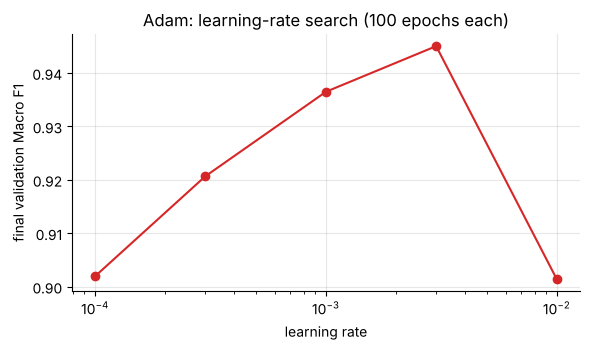

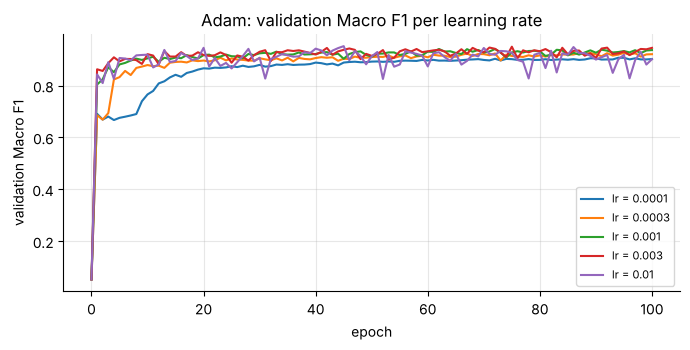

In [18]:
OPT = "Adam"
best_lr, lr_df, lr_hists = lr_search(d, OPT)
lr_df.to_csv(os.path.join(RESULTS, f"lr_search_{OPT}.csv"), index=False)
display(lr_df.round(4))
print("selected learning rate:", best_lr, "| value found by src/experiment_runner.py:", 0.003,
      "| match:", best_lr == 0.003)
lr_search_plot(lr_df, OPT, "05_lr_search.png")
fig, ax = plt.subplots(figsize=(7, 3.6))
for lr, h in lr_hists.items():
    if not h["diverged"]:
        ax.plot(h["val_f1"], label=f"lr = {lr:g}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation Macro F1"); ax.set_title(OPT + ": validation Macro F1 per learning rate"); ax.legend(fontsize=8)
save(fig, "05_lr_curves.png")

In [19]:
res = fit_and_evaluate(d, OPT, best_lr)        # final training run with the selected learning rate
h = res["history"]
print(f"epochs = {len(h['train_obj']) - 1} | parameter updates = {h['updates'][-1]:,} | samples processed = {h['samples'][-1]:,}")
print(f"training time = {h['train_time'][-1]:.2f} s | final J = {res['obj_train']['total']:.4f} "
      f"(hinge {res['obj_train']['hinge']:.4f} + RKHS reg {res['obj_train']['reg']:.4f})")
hist_df = history_frame(h); hist_df.to_csv(os.path.join(RESULTS, "training_histories", f"{OPT}.csv"), index=False)
display(hist_df.iloc[[0, 1, 2, 5, 10, 25, 50, 75, 100]].round(4))

epochs = 100 | parameter updates = 8,700 | samples processed = 555,100
training time = 37.87 s | final J = 0.1592 (hinge 0.1135 + RKHS reg 0.0457)


,epoch,train_hinge,train_reg,train_obj,val_hinge,val_obj,train_acc,val_acc,train_f1,val_f1,updates,samples,train_time,eff_lr
0,0,1.0000,0.0000,1.0000,1.0000,1.0000,0.1600,0.1877,0.0460,0.0527,0,0,0.0000,0.0030
1,1,0.4239,0.0130,0.4369,0.4141,0.4271,0.8537,0.8745,0.8501,0.8625,87,5551,0.3493,0.4235
2,2,0.3377,0.0168,0.3545,0.3836,0.4004,0.8863,0.8679,0.8868,0.8561,174,11102,0.7605,0.5515
5,5,0.2315,0.0264,0.2579,0.2657,0.2921,0.9274,0.9028,0.9301,0.8929,435,27755,1.8899,0.8211
10,10,0.1745,0.0322,0.2067,0.2141,0.2463,0.9422,0.9245,0.9454,0.9208,870,55510,3.5930,1.1442
25,25,0.1453,0.0395,0.1847,0.2472,0.2866,0.9521,0.8995,0.9543,0.8877,2175,138775,9.4377,1.9015
50,50,0.1366,0.0425,0.1792,0.2391,0.2816,0.9578,0.9173,0.9608,0.9142,4350,277550,19.1394,2.6165
75,75,0.1033,0.0461,0.1494,0.1646,0.2107,0.9683,0.9517,0.9698,0.9496,6525,416325,28.5519,2.7241
100,100,0.1135,0.0457,0.1592,0.1755,0.2212,0.9658,0.9484,0.9676,0.9450,8700,555100,37.8656,2.6641


## 20. Model Evaluation
Metrics on the **independent test set** (9 unseen subjects), computed manually from the confusion matrix and
verified against scikit-learn. The training objective (hinge + RKHS regularisation) is reported separately from the
evaluation metrics. ROC-AUC is One-vs-Rest from the raw decision scores (rank-based, no probabilities assumed);
no log-loss is reported because SVM scores are not calibrated probabilities.

,Adam
optimizer,Adam
learning_rate,0.003
batch_size,64
epochs,100
updates,8700
samples_processed,555100
accuracy,0.927044
macro_precision,0.929973
macro_recall,0.92544
macro_f1,0.925228


max |manual - sklearn| metric difference: 2.220446049250313e-16


,precision,recall,f1,support
WALKING,0.9668,0.9395,0.9530,496
WALKING_UPSTAIRS,0.9332,0.9788,0.9554,471
WALKING_DOWNSTAIRS,0.9009,0.9095,0.9052,420
SITTING,0.9545,0.7699,0.8523,491
STANDING,0.8410,0.9643,0.8984,532
LAYING,0.9834,0.9907,0.9870,537
macro avg,0.9300,0.9254,0.9252,2947
weighted avg,0.9303,0.9270,0.9261,2947


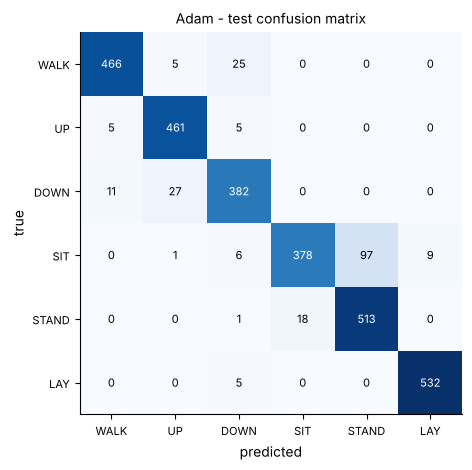

In [20]:
t = res["test"]
summary = pd.DataFrame([summary_row(OPT, res)]).T.rename(columns={0: OPT})
display(summary)
print("max |manual - sklearn| metric difference:", verify_with_sklearn(d["y_te"], np.argmax(decision_scores(d["H_te"], res["A"], res["b"]), 1), t))
report = classification_report_df(t, ACTIVITY_LABELS); display(report)
report.to_csv(os.path.join(RESULTS, "metrics", f"{OPT}_classification_report.csv"))
json.dump({k: (v.tolist() if hasattr(v, "tolist") else v) for k, v in t.items()},
          open(os.path.join(RESULTS, "metrics", f"{OPT}_test_metrics.json"), "w"), indent=1)
confusion(t["confusion_matrix"], ACTIVITY_LABELS, f"{OPT} - test confusion matrix", "05_confusion_matrix.png")

In [21]:
# Save the model with everything needed for inference (basis, gamma, scaler, labels), reload and re-predict
model = build_model(d, res)
path = os.path.join(MODELS, MODEL_FILES[OPT])
model.save(path, optimizer=OPT, learning_rate=best_lr, basis_idx=d["basis_idx"])
loaded = KernelMulticlassSVM.load(path)
pred_loaded = loaded.predict(raw["X_test"].to_numpy(float))
print("saved:", path, f"({os.path.getsize(path) / 1e6:.1f} MB)")
print("reloaded model reproduces the test predictions:", np.array_equal(pred_loaded, np.argmax(decision_scores(d["H_te"], res["A"], res["b"]), 1)))

saved: /home/claude/A4/Assignment_4_Kernel_Multiclass_SVM/models/kernel_svm_adam.npz (8.2 MB)
reloaded model reproduces the test predictions: True


## 21. Visualizations

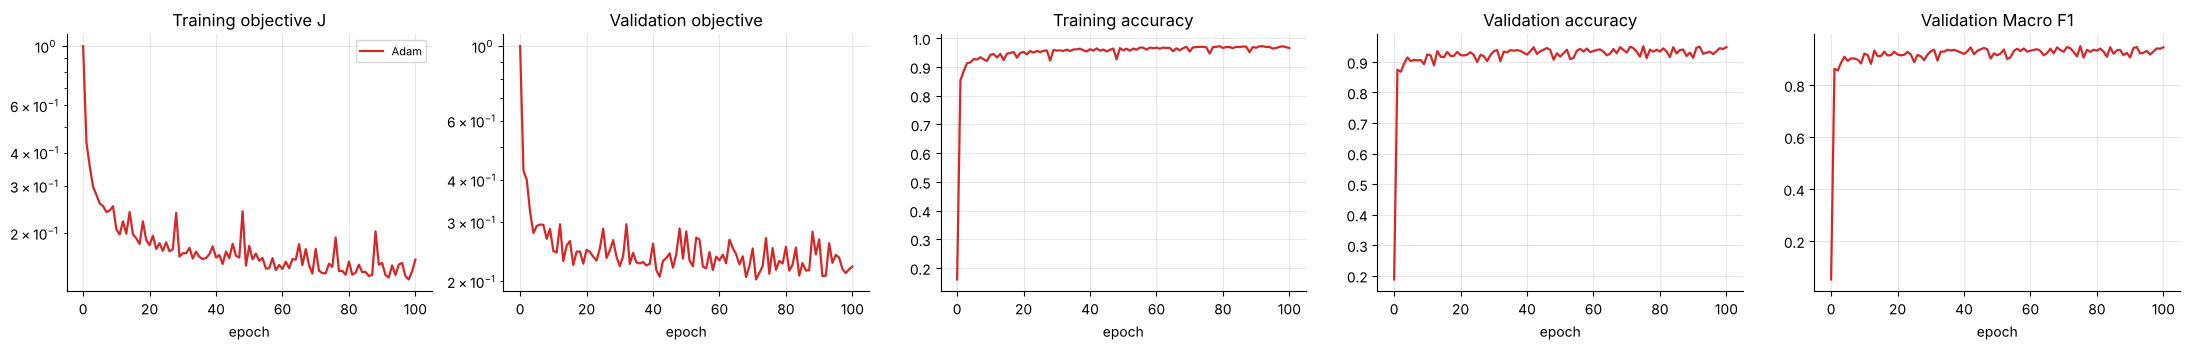

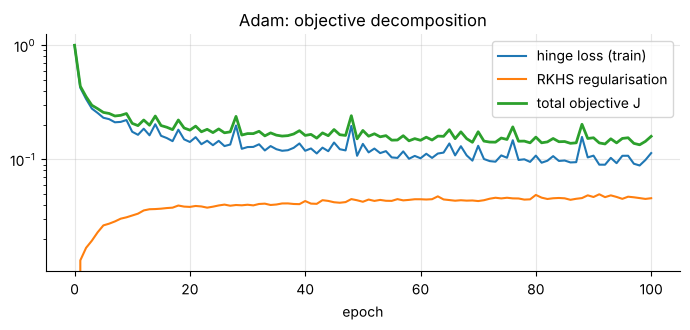

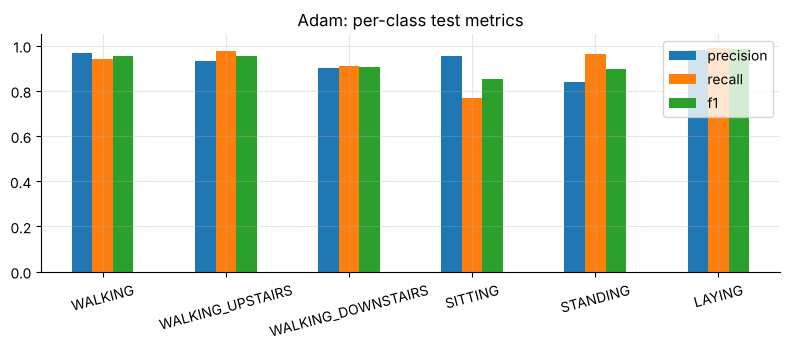

In [22]:
training_curves({OPT: h}, keys=("train_obj", "val_obj", "train_acc", "val_acc", "val_f1"), name="05_training_curves.png")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(h["train_hinge"], label="hinge loss (train)"); ax.plot(h["train_reg"], label="RKHS regularisation")
ax.plot(h["train_obj"], label="total objective J", lw=2); ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.legend()
ax.set_title(OPT + ": objective decomposition"); save(fig, "05_objective_parts.png")
per = pd.DataFrame({"precision": t["per_class_precision"], "recall": t["per_class_recall"], "f1": t["per_class_f1"]}, index=ACTIVITY_LABELS)
ax = per.plot.bar(figsize=(8, 3.6), rot=15, ylim=(0, 1.05), title=OPT + ": per-class test metrics"); save(ax.figure, "05_per_class.png")

## Final optimizer comparison (all five optimizers)
To keep this notebook stand-alone, the four other optimizers are re-trained here with the learning rates selected
in their own notebooks (embedded below and identical to `results/hyperparameters.json`); training is deterministic,
so the metrics reproduce those notebooks exactly (training times vary slightly between runs).

In [23]:
SELECTED_LR = {'GD': 1.0, 'SGD': 0.003, 'MBGD': 0.1, 'AdaGrad': 0.1, 'Adam': 0.003}
all_res = {}
for o in ("GD", "SGD", "MBGD", "AdaGrad"):
    all_res[o] = fit_and_evaluate(d, o, SELECTED_LR[o]); print(o, "done", round(all_res[o]["history"]["train_time"][-1], 1), "s")
all_res["Adam"] = res
assert best_lr == SELECTED_LR["Adam"]
comp = pd.DataFrame([summary_row(o, r) for o, r in all_res.items()])
comp.to_csv(os.path.join(RESULTS, "optimizer_comparison.csv"), index=False)
for o, r in all_res.items():
    history_frame(r["history"]).to_csv(os.path.join(RESULTS, "training_histories", f"{o}.csv"), index=False)
table = comp[["optimizer", "accuracy", "macro_precision", "macro_recall", "macro_f1", "train_hinge", "regularization",
              "train_objective", "training_time_s", "prediction_time_s"]].rename(columns={
    "optimizer": "Optimizer", "accuracy": "Accuracy", "macro_precision": "Macro Precision", "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1", "train_hinge": "Hinge Loss", "regularization": "Regularization Loss", "train_objective": "Total Objective",
    "training_time_s": "Training Time (s)", "prediction_time_s": "Prediction Time (s)"})
display(table.round(4))
display(comp[["optimizer", "learning_rate", "batch_size", "epochs", "updates", "samples_processed", "val_macro_f1",
              "val_accuracy", "roc_auc_ovr", "pct_epochs_obj_increased", "tail_rel_std", "prediction_time_with_kernel_s"]].round(4))

GD done 5.2 s


SGD done 11.3 s


MBGD done 35.6 s


AdaGrad done 36.0 s


,Optimizer,Accuracy,Macro Precision,Macro Recall,Macro F1,Hinge Loss,Regularization Loss,Total Objective,Training Time (s),Prediction Time (s)
0,GD,0.8646,0.8730,0.8589,0.8577,0.4257,0.1513,0.5771,5.2346,0.0096
1,SGD,0.9359,0.9343,0.9333,0.9333,0.0993,0.0397,0.1391,11.3368,0.0093
2,MBGD,0.9237,0.9239,0.9206,0.9210,0.1290,0.0384,0.1674,35.6396,0.0091
3,AdaGrad,0.9382,0.9369,0.9366,0.9365,0.1041,0.0402,0.1443,35.9621,0.0127
4,Adam,0.9270,0.9300,0.9254,0.9252,0.1135,0.0457,0.1592,37.8656,0.0146


,optimizer,learning_rate,batch_size,epochs,updates,samples_processed,val_macro_f1,val_accuracy,roc_auc_ovr,pct_epochs_obj_increased,tail_rel_std,prediction_time_with_kernel_s
0,GD,1.000,NaN,100,100,555100,0.8561,0.8673,0.9668,55.0,0.6174,0.1613
1,SGD,0.003,1.0,100,555100,555100,0.9316,0.9373,0.9885,46.0,0.0625,0.1610
2,MBGD,0.100,64.0,100,8700,555100,0.9296,0.9350,0.9877,46.0,0.2470,0.1194
3,AdaGrad,0.100,64.0,100,8700,555100,0.9405,0.9445,0.9875,46.0,0.1097,0.1519
4,Adam,0.003,64.0,100,8700,555100,0.9450,0.9484,0.9883,46.0,0.0983,0.1907


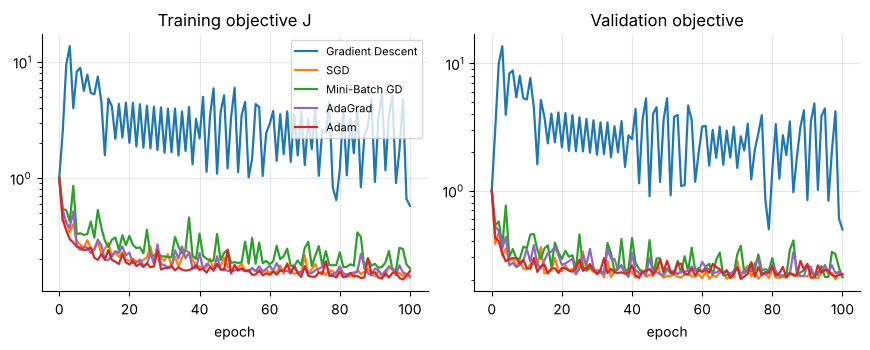

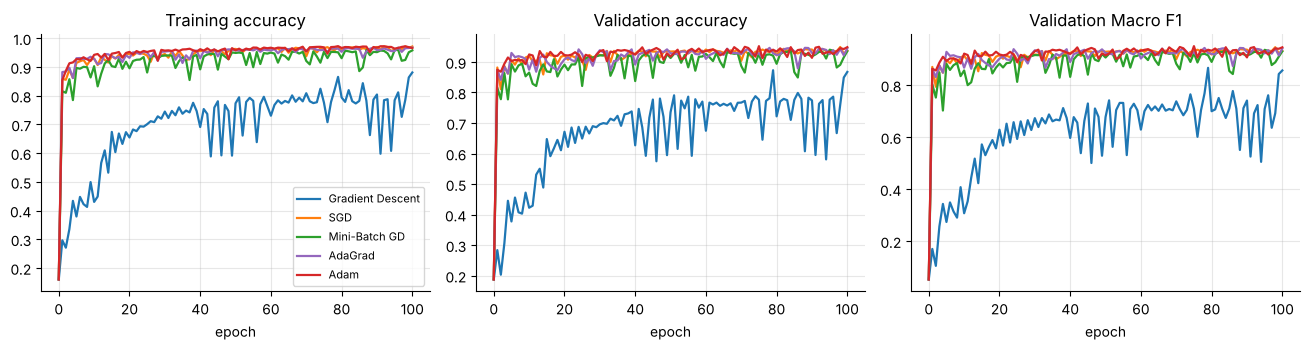

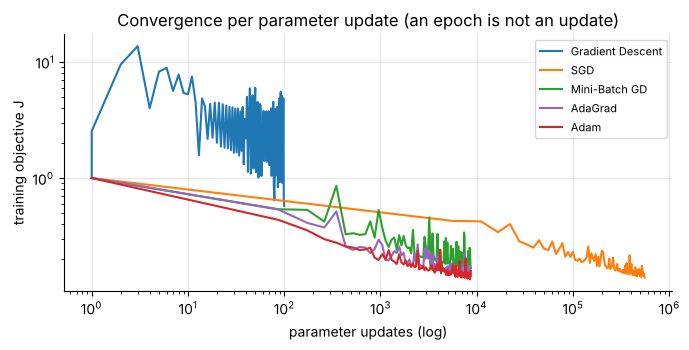

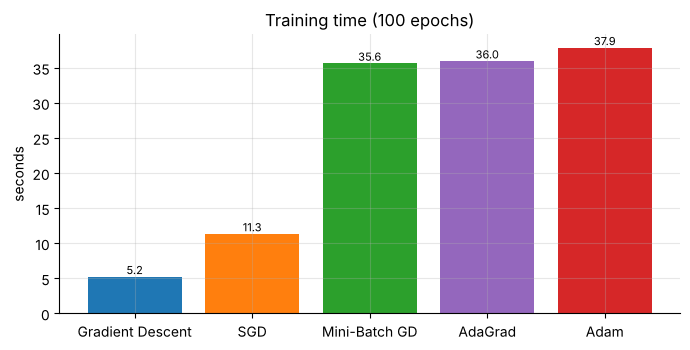

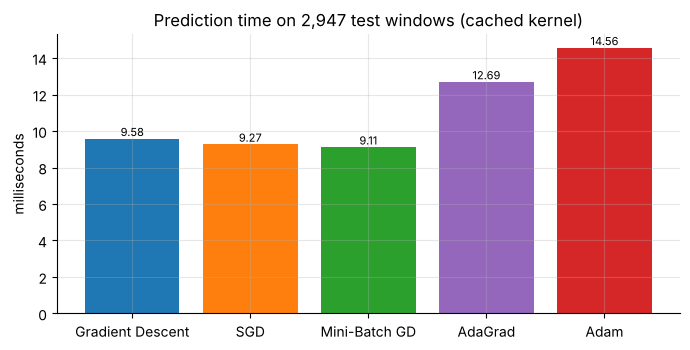

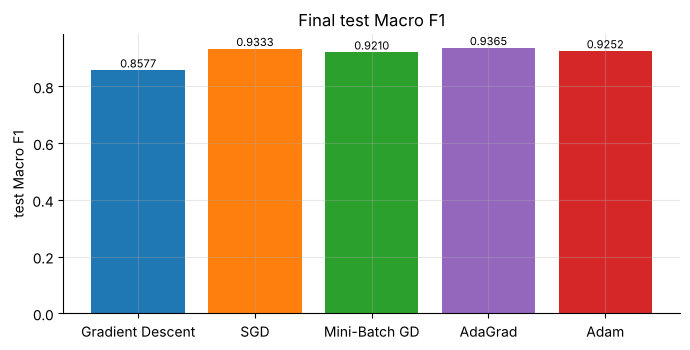

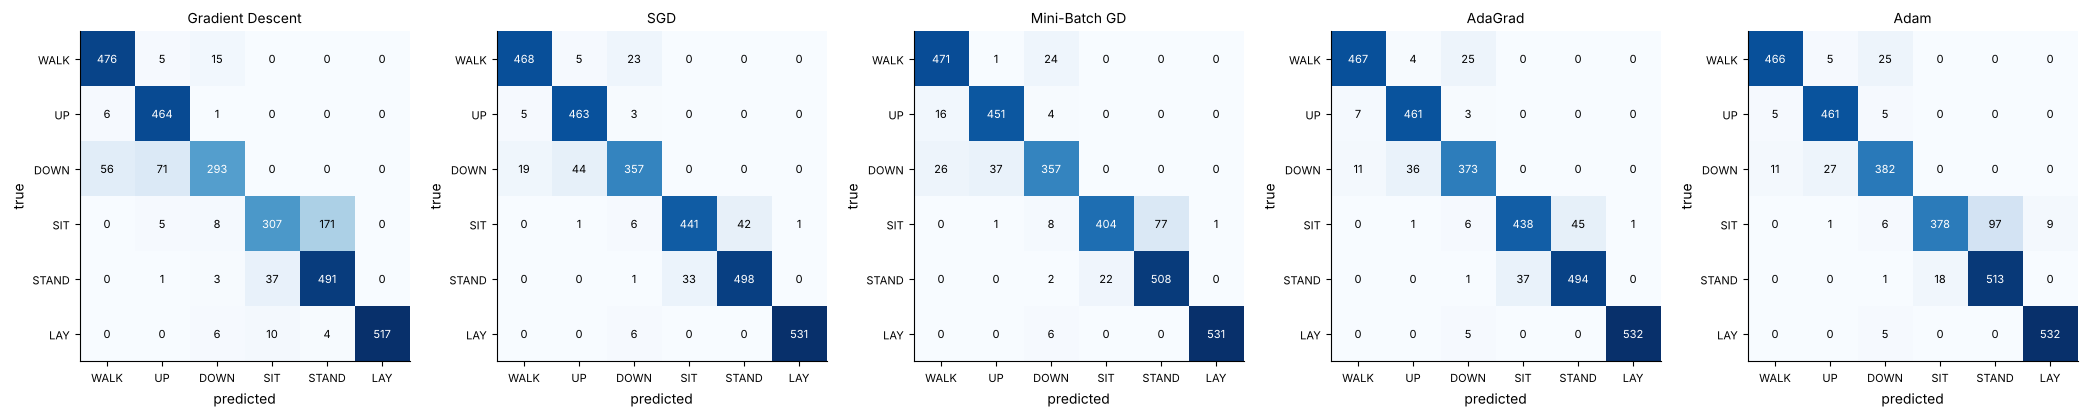

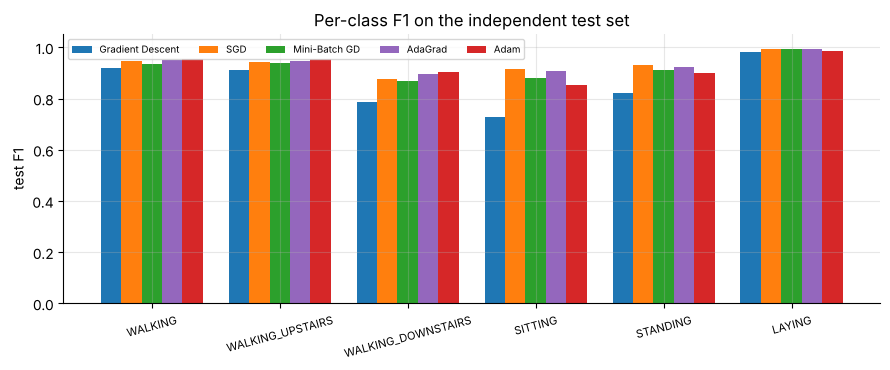

,GD,SGD,MBGD,AdaGrad,Adam
WALKING,0.9207,0.9474,0.9336,0.9521,0.9530
WALKING_UPSTAIRS,0.9125,0.9411,0.9386,0.9476,0.9554
WALKING_DOWNSTAIRS,0.7855,0.8750,0.8697,0.8956,0.9052
SITTING,0.7266,0.9140,0.8811,0.9068,0.8523
STANDING,0.8197,0.9291,0.9096,0.9225,0.8984
LAYING,0.9810,0.9935,0.9935,0.9944,0.9870


In [24]:
H = {o: r["history"] for o, r in all_res.items()}
training_curves(H, keys=("train_obj", "val_obj"), name="05_loss_curves_all.png")
training_curves(H, keys=("train_acc", "val_acc", "val_f1"), name="05_accuracy_f1_curves_all.png")
fig, ax = plt.subplots(figsize=(7, 3.6))
for o, hh in H.items():
    ax.plot(np.maximum(hh["updates"], 1), hh["train_obj"], color=COLORS[o], label=NAMES[o])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("parameter updates (log)"); ax.set_ylabel("training objective J")
ax.set_title("Convergence per parameter update (an epoch is not an update)"); ax.legend(fontsize=8); save(fig, "05_convergence_vs_updates.png")
bar_compare({o: r["history"]["train_time"][-1] for o, r in all_res.items()}, "seconds", "Training time (100 epochs)", "05_training_time.png", "{:.1f}")
bar_compare({o: 1000 * r["pred_time"] for o, r in all_res.items()}, "milliseconds", "Prediction time on 2,947 test windows (cached kernel)", "05_prediction_time.png", "{:.2f}")
bar_compare({o: r["test"]["macro_f1"] for o, r in all_res.items()}, "test Macro F1", "Final test Macro F1", "05_final_macro_f1.png", "{:.4f}")
confusion_grid({o: r["test"]["confusion_matrix"] for o, r in all_res.items()}, ACTIVITY_LABELS, "05_confusion_matrices_all.png")
per_class_f1({o: r["test"]["per_class_f1"] for o, r in all_res.items()}, ACTIVITY_LABELS, "05_per_class_f1.png")
pc = pd.DataFrame({o: r["test"]["per_class_f1"] for o, r in all_res.items()}, index=ACTIVITY_LABELS)
pc.to_csv(os.path.join(RESULTS, "per_class_f1.csv")); display(pc.round(4))

In [25]:
# Automatic determination of the "winners" (evidence from the table above)
target = 1.10 * comp.train_objective.min()
def epochs_to(hh, thr):
    hit = np.flatnonzero(np.asarray(hh["train_obj"]) <= thr)
    return int(hit[0]) if len(hit) else None
conv = {o: epochs_to(r["history"], target) for o, r in all_res.items()}
# efficiency: the fastest optimizer among those within 1 Macro-F1 point of the best test Macro F1
near_best = comp[comp.macro_f1 >= comp.macro_f1.max() - 0.01]
eff_winner = near_best.loc[near_best.training_time_s.idxmin(), "optimizer"]
best_class = {c: pc.loc[c].idxmax() for c in ACTIVITY_LABELS}
verdict = {
    "best_by_validation_macro_f1": comp.loc[comp.val_macro_f1.idxmax(), "optimizer"],
    "highest_test_accuracy": comp.loc[comp.accuracy.idxmax(), "optimizer"],
    "lowest_training_objective": comp.loc[comp.train_objective.idxmin(), "optimizer"],
    "fastest_training": comp.loc[comp.training_time_s.idxmin(), "optimizer"],
    "convergence_target_J": round(float(target), 4), "epochs_to_target": conv,
    "fastest_convergence_epochs": min((v, o) for o, v in conv.items() if v is not None)[1],
    "most_stable_epoch_level (lowest % epochs with J increase, then tail std)": comp.sort_values(["pct_epochs_obj_increased", "tail_rel_std"]).iloc[0]["optimizer"],
    "best_efficiency (fastest within 1 Macro-F1 point of the best)": eff_winner,
    "best_per_class_f1": best_class}
json.dump(verdict, open(os.path.join(RESULTS, "optimizer_verdict.json"), "w"), indent=2)
print(json.dumps(verdict, indent=2))

{
  "best_by_validation_macro_f1": "Adam",
  "highest_test_accuracy": "AdaGrad",
  "lowest_training_objective": "SGD",
  "fastest_training": "GD",
  "convergence_target_J": 0.153,
  "epochs_to_target": {
    "GD": null,
    "SGD": 60,
    "MBGD": null,
    "AdaGrad": 66,
    "Adam": 49
  },
  "fastest_convergence_epochs": "Adam",
  "most_stable_epoch_level (lowest % epochs with J increase, then tail std)": "SGD",
  "best_efficiency (fastest within 1 Macro-F1 point of the best)": "SGD",
  "best_per_class_f1": {
    "WALKING": "Adam",
    "WALKING_UPSTAIRS": "Adam",
    "WALKING_DOWNSTAIRS": "Adam",
    "SITTING": "SGD",
    "STANDING": "SGD",
    "LAYING": "AdaGrad"
  }
}


## 22. Results Interpretation
* Selected learning rate **0.003**; 8,700 parameter updates in 100 epochs (555,100 processed samples).
* Validation Macro F1 **0.9450** (rank 1/5 - the selection metric); test accuracy **92.70%**, test Macro F1 **0.9252** (rank 3/5), OvR ROC-AUC 0.9883.
* Final training objective J = 0.1592 = hinge 0.1135 + RKHS regularisation 0.0457; the training objective increased in 46% of the epochs.
* **Best optimizer by validation Macro F1 (the pre-registered selection rule): Adam** (0.9450).
* Highest independent test accuracy: **AdaGrad** (93.82%); highest test Macro F1: **AdaGrad** (0.9365). The validation winner and the test winner differ - with only 5 validation subjects, differences of about 1 point are within subject-to-subject variability.
* Lowest training objective: **SGD** (J = 0.1391); fastest training: **Gradient Descent**.
* Fastest convergence (first epoch with J <= 0.1530, i.e. 1.1 x the lowest final J): **Adam**; epochs to target: {'GD': None, 'SGD': 60, 'MBGD': None, 'AdaGrad': 66, 'Adam': 49}.
* Most stable at epoch level (fewest epochs in which J increased): **SGD** (within an epoch SGD is the noisiest - see notebook 02); best efficiency (fastest optimizer within 1 Macro-F1 point of the best): **SGD**.
* GD is far behind (test Macro F1 0.8577) because 100 epochs = 100 updates.
* Adam is **not** automatically the best: it wins on validation but not on the test subjects.
* SITTING and STANDING are the most confused pair (static postures with similar sensor statistics); LAYING and the walking classes are recognised almost perfectly.

## 23. Conclusion
All five manually implemented optimizers minimise the same RKHS-regularised Crammer-Singer objective under identical conditions. Stochastic and adaptive methods (SGD, AdaGrad, Adam, Mini-Batch GD) reach 92-94% test accuracy within 100 epochs, while full-batch GD needs far more iterations. The ranking between the top four depends on the split (validation vs test), so the honest conclusion is that they are statistically close; among them SGD needed the least training time thanks to its exact O(MK) rotated update.

## 24. References
1. D. Anguita, A. Ghio, L. Oneto, X. Parra, J. L. Reyes-Ortiz. *A Public Domain Dataset for Human Activity Recognition Using Smartphones.* ESANN 2013.
2. C. Cortes, V. Vapnik. *Support-Vector Networks.* Machine Learning 20, 1995.
3. K. Crammer, Y. Singer. *On the Algorithmic Implementation of Multiclass Kernel-based Vector Machines.* JMLR 2, 2001.
4. B. Schoelkopf, R. Herbrich, A. Smola. *A Generalized Representer Theorem.* COLT 2001.
5. B. Schoelkopf, A. Smola. *Learning with Kernels.* MIT Press, 2002.
6. C. Williams, M. Seeger. *Using the Nystroem Method to Speed Up Kernel Machines.* NIPS 2001.
7. A. Rahimi, B. Recht. *Random Features for Large-Scale Kernel Machines.* NIPS 2007.
8. J. Duchi, E. Hazan, Y. Singer. *Adaptive Subgradient Methods for Online Learning and Stochastic Optimization.* JMLR 2011.
9. D. P. Kingma, J. Ba. *Adam: A Method for Stochastic Optimization.* ICLR 2015.
10. C.-C. Chang, C.-J. Lin. *LIBSVM: A Library for Support Vector Machines.* ACM TIST 2011 (used by scikit-learn `SVC`).